# Walmart Weekly Sales — Projet Machine Learning Bloc 3

Copyright © 2026 · voir le fichier LICENSE du dépôt

**Certification :** Concepteur Développeur en Science des Données (CDSD, RNCP35288) — Bloc 3
**Bloc visé :** Analyse prédictive de données structurées par l'intelligence artificielle
**Cas traité :** prédiction des ventes hebdomadaires Walmart (`Weekly_Sales`) à partir de variables magasin, calendrier et contexte économique.
**Livrable :** notebook explicatif, reproductible et commenté.

## Verdict

Le modèle retenu, son hyperparamètre `alpha` et ses scores (RMSE, MAE, R² sur le jeu de test) sont **calculés puis affichés** par la cellule de la section 12, et repris par la conclusion (section 20). Aucun de ces chiffres n'est écrit à la main dans ce texte : ils changent si les données ou la procédure changent.

Ce résultat doit être lu avec prudence : le jeu exploitable est petit (**131 lignes après nettoyage**, 19 magasins). Le notebook ne cherche donc pas seulement à maximiser une métrique : il documente les choix, les alternatives rejetées, les risques de fuite de données, les limites statistiques et la stabilité du résultat quand on change le découpage (section 17).

## Mode de lecture conseillé

1. **Sections 0 à 6** : cadrage, audit, EDA et nettoyage imposé par l'énoncé (dont une conséquence à connaître : le magasin 12 disparaît).
2. **Sections 7 à 17** : pipeline supervisé complet, choix de `alpha` par validation croisée, évaluation, coefficients (avec leurs limites), diagnostic d'erreur et stabilité sur plusieurs découpages.
3. **Section 18** : segmentation non supervisée ajoutée pour couvrir explicitement la compétence Bloc 3 liée au clustering.
4. **Sections 19 à 24** : RGPD, conclusion, recommandations calculées, questions probables et références.

**Position assumée :** le modèle est volontairement interprétable. Sur un jeu aussi petit, un modèle plus complexe pourrait améliorer localement un score, mais serait moins défendable et plus exposé au sur-apprentissage.

---

## Documentation vivante de ce notebook

Cinq rubriques, relues à chaque modification du code : elles disent ce qui a été décidé, où cela vit, comment cela marche et ce qui le prouve.

## CHOIX

- Retenu : un notebook explicatif (le raisonnement reste dans les cellules Markdown) adossé à un module `walmart_bloc3.py`, placé à côté de lui, qui contient les fonctions de calcul. Ces fonctions sont testées sans exécuter le notebook (`tests/test_walmart_bloc3.py:125`), et un test d'intégration exécute le notebook entier et vérifie ses chiffres clés (`tests/test_notebook_walmart.py:88`).
- Retenu : ce que le jury peut vouloir modifier en direct reste dans les cellules, pas dans le module : `RANDOM_STATE` (cellule 3), `OUTLIER_COLS` et `N_SIGMA` (cellule 9), les listes de variables, le préprocesseur et les grilles d'`alpha`.
- Retenu pour le modèle : prétraitement scikit-learn dans un `Pipeline` (pas de fuite de données), régression linéaire, Ridge et Lasso comparés sur le RMSE de validation croisée de l'apprentissage, `alpha` choisi par `GridSearchCV` sur une grille logarithmique.
- Écartés, avec la raison : imputer la cible (cela fabrique des ventes), traiter `Store` comme un nombre, `LabelEncoder` (ordre artificiel), choisir le modèle sur le jeu de test (la mesure finale devient optimiste), forêts et gradient boosting (hors exigence, moins interprétables sur 131 lignes), découpage temporel strict (jeu réduit). Le détail est dans la section 22.
- Écarté pour la conformité : garder les fonctions dans les cellules sans test ; elles ne se vérifiaient qu'en relançant tout le notebook.

## OÙ

- Rôle : livrable du bloc 3 CDSD (RNCP35288) sur les ventes hebdomadaires Walmart. Il n'a pas d'appelant : c'est un document final, relu et exécuté de haut en bas.
- Il appelle `walmart_bloc3.py` (fonctions de calcul) et lit `Walmart_Store_sales.csv`, placé à côté de lui. Il écrit neuf fichiers de contrôle dans `walmart_bloc3_exam_outputs/` (cellule 36), par exemple `walmart_bloc3_exam_outputs/model_metrics.csv:2`.
- Dépendances : numpy, pandas, scikit-learn, matplotlib et IPython, aux versions épinglées dans `requirements.txt` (celles que la cellule 3 affiche). Les outils de test sont dans `requirements-dev.txt`.

## COMMENT

- Les sections 1 à 24 se lisent dans l'ordre : chargement et audit (1 à 3), exploration (5), nettoyage imposé (6), pipeline (7 à 9), modèles et choix d'`alpha` (10 à 13), coefficients (14), diagnostic d'erreur (15), validation croisée (16), stabilité sur 40 découpages (17), segmentation des magasins (18), conclusion et recommandations calculées (20, 21).
- Reproductibilité : les graines sont fixées (`RANDOM_STATE = 42` ; graines 0 à 39 pour la section 17) ; la cellule 3 affiche les versions des bibliothèques.
- Tests : `python -m pytest tests -W error::DeprecationWarning -W error::PendingDeprecationWarning`. Les tests du module sont rapides ; le test du notebook (`-m notebook`) l'exécute en entier, environ deux minutes. Un test relance aussi les cellules 0 à 9 avec `Unemployment` retiré de `OUTLIER_COLS` et vérifie que la cellule 9 ne plante plus (`tests/test_notebook_walmart.py:118`).
- Les textes calculés suivent les réglages de la cellule 9 : la conclusion (cellule 32) lit le nombre de lignes et les magasins retirés au lieu de les écrire à la main. Les cellules Markdown, elles, restent un texte fixe écrit pour les réglages d'origine (131 lignes, 19 magasins, 3 écarts-types).

## POURQUOI

- Référentiel : RNCP35288, bloc 3, https://www.francecompetences.fr/recherche/rncp/35288/ ; documentation scikit-learn de `Pipeline`, `ColumnTransformer` et `GridSearchCV` (section 24).
- Les chiffres cités dans le texte sont calculés par le notebook et écrits dans `walmart_bloc3_exam_outputs/model_metrics.csv:2` ; aucun n'est saisi à la main.
- La règle moyenne ± 3 écarts-types sur `Temperature`, `Fuel_Price`, `CPI` et `Unemployment` vient de l'énoncé du projet, fourni par l'organisme de formation et non redistribué ici.
- Les seuils de lecture du diagnostic de sur-apprentissage (0,5 ; 0,10 ; 0,02) sont des conventions de lecture du notebook : source : inconnue, sans référence externe.

## JOURNALISATION

- Le notebook ne journalise pas dans un fichier : ses affichages font le journal. Cellule 3 : versions de Python et des bibliothèques. Cellule 9 : journal de nettoyage (lignes avant et après chaque étape), seuils appliqués, lignes et magasins retirés. Section 17 : les avertissements de scikit-learn sont comptés découpage par découpage, jamais masqués. Cellule 36 : liste des fichiers écrits.
- Aucune donnée personnelle n'est lue ni écrite (section 19).
- Le module `walmart_bloc3.py` ne journalise rien ; ses fonctions sont pures et rendent leurs avertissements à l'appelant.


<style>
/* --------------------------------------------------------------------------
   Bloc 3 notebook cosmetics
   Objectif : tables lisibles, sans effet "bloc de code brut".
   -------------------------------------------------------------------------- */
.bloc3-table-wrap {
    overflow-x: auto;
    margin: 0.75rem 0 1.25rem 0;
}
.bloc3-table {
    border-collapse: collapse;
    font-size: 0.92rem;
    line-height: 1.35;
    width: auto;
    min-width: 60%;
}
.bloc3-table th {
    background: #eef2f7;
    color: #1f2937;
    font-weight: 700;
    border: 1px solid #d0d7de;
    padding: 6px 9px;
    text-align: left;
    white-space: nowrap;
}
.bloc3-table td {
    border: 1px solid #d8dee4;
    padding: 6px 9px;
    white-space: nowrap;
    vertical-align: top;
}
.bloc3-table tr:nth-child(even) td {
    background: #fafbfc;
}
.bloc3-callout {
    border-left: 4px solid #2563eb;
    background: #f8fafc;
    padding: 0.75rem 1rem;
    margin: 0.8rem 0 1.1rem 0;
}
.bloc3-decision {
    border-left: 4px solid #059669;
    background: #ecfdf5;
    padding: 0.75rem 1rem;
    margin: 0.8rem 0 1.1rem 0;
}
.bloc3-warning {
    border-left: 4px solid #d97706;
    background: #fffbeb;
    padding: 0.75rem 1rem;
    margin: 0.8rem 0 1.1rem 0;
}
</style>

## 0. Grille de lecture Bloc 3

| Compétence attendue Bloc 3 | Traitement dans ce notebook |
|---|---|
| Traiter des données structurées avec un pipeline | `Pipeline` + `ColumnTransformer`, imputation, encodage, normalisation (sections 6 à 9) |
| Encoder, normaliser et découper les données | `OneHotEncoder`, `StandardScaler`, `train_test_split` |
| Réaliser une analyse prédictive supervisée | `LinearRegression`, `Ridge`, `Lasso`, `GridSearchCV` sur une grille logarithmique (section 11) |
| Évaluer la performance prédictive | RMSE, MAE, R², train/test, référence naïve, validation croisée, plusieurs découpages (sections 12, 16, 17) |
| Déterminer l'influence des variables | Coefficients du modèle retenu, colinéarité, intervalles par bootstrap (section 14) |
| Couvrir la compétence non supervisée C3.3 | Section 18 : segmentation des magasins par `KMeans` + visualisation `PCA` |

Le projet Walmart est naturellement un problème supervisé de régression. Une section non supervisée séparée démontre la compétence de segmentation sans mélanger les objectifs métier.

In [1]:
# =============================================================================
# 1. Imports, environnement et configuration générale
# =============================================================================
# Objectif : préparer un environnement d'exécution stable et reproductible.
#
# Tous les imports sont regroupés ici, en tête du notebook : c'est la convention
# PEP 8 (imports en début de fichier, groupés : bibliothèque standard, puis
# bibliothèques tierces). On voit ainsi d'un coup d'œil de quoi dépend le projet.

# --- Bibliothèque standard ---------------------------------------------------
import os
import platform
import sys
from pathlib import Path

# Limitation défensive des threads numériques, posée AVANT le chargement de NumPy
# et de scikit-learn : sur certains environnements elle évite des blocages OpenMP
# avec KMeans. Elle ne change pas les résultats, seulement la stabilité.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

# Le module walmart_bloc3.py (les fonctions de calcul, testées dans tests/) est à côté de ce
# notebook. Le noyau Jupyter ne démarre pas toujours dans ce dossier : on l'ajoute au chemin
# d'import AVANT de l'importer, en remontant depuis le dossier courant (comme trouver_racine).
sys.path.insert(
    0,
    str(
        next(
            (
                dossier
                for parent in (Path.cwd(), *Path.cwd().parents)
                for dossier in (parent, parent / "1_Walmart")
                if (dossier / "walmart_bloc3.py").exists()
            ),
            Path.cwd(),
        )
    ),
)

# --- Bibliothèques tierces ---------------------------------------------------
# Les commentaires « type: ignore » disent à mypy que pandas et scikit-learn ne publient pas
# de types : ils ne changent rien à l'exécution.
import IPython
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # type: ignore[import-untyped]
import sklearn  # type: ignore[import-untyped]
from sklearn.base import clone  # type: ignore[import-untyped]
from sklearn.cluster import KMeans  # type: ignore[import-untyped]
from sklearn.compose import ColumnTransformer  # type: ignore[import-untyped]
from sklearn.decomposition import PCA  # type: ignore[import-untyped]
from sklearn.dummy import DummyRegressor  # type: ignore[import-untyped]
from sklearn.impute import SimpleImputer  # type: ignore[import-untyped]
from sklearn.linear_model import Lasso, LinearRegression, Ridge  # type: ignore[import-untyped]
from sklearn.metrics import silhouette_score  # type: ignore[import-untyped]
from sklearn.model_selection import (  # type: ignore[import-untyped]
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline  # type: ignore[import-untyped]
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # type: ignore[import-untyped]

# --- Fonctions de calcul du projet (module testé, à côté du notebook) -------------
from walmart_bloc3 import (
    RMSE_SCORER,
    afficher,
    afficher_markdown,
    build_pipeline,
    chercher_alpha,
    consequences_pretraitement,
    diagnostic_validation,
    evaluate_model,
    evaluer_un_decoupage,
    fr,
    part_entre_magasins,
    phrase_variable,
    prepare_dataframe,
    r2_regression,
    trouver_racine,
)

# Rôle de chaque famille d'imports :
# - pandas / numpy : données tabulaires et calcul numérique ;
# - matplotlib : graphiques simples et lisibles (pas de bibliothèque plus lourde) ;
# - IPython : version affichée plus bas ; l'affichage passe par afficher() du module ;
# - scikit-learn : Pipeline + ColumnTransformer (prétraitement sans fuite), modèles
#   linéaires demandés par l'énoncé (régression linéaire, Ridge, Lasso), validation
#   croisée, métriques, KMeans et PCA pour la section non supervisée ;
# - clone : copie d'un estimateur non ajusté (chaque modèle a son propre prétraitement).

# RANDOM_STATE fixe tous les tirages pseudo-aléatoires. Sans cela, le découpage
# train/test, la validation croisée et KMeans changeraient d'une exécution à l'autre :
# on doit pouvoir relancer le notebook et retrouver les mêmes chiffres.
RANDOM_STATE = 42

# Dossier du projet. Le noyau Jupyter ne démarre pas toujours dans le dossier du notebook
# (selon l'éditeur, le dossier de travail peut être le dossier parent, ou ailleurs). On
# cherche donc le dossier qui CONTIENT ce notebook, en remontant depuis le dossier courant ;
# à défaut, on garde le dossier courant.
NOM_NOTEBOOK = "Walmart_Bloc3_CDSD_v2.ipynb"
PROJECT_ROOT = trouver_racine(NOM_NOTEBOOK, "1_Walmart")

# Chemin du jeu de données : le CSV est placé dans le même dossier que le notebook.
DATA_PATH = PROJECT_ROOT / "Walmart_Store_sales.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Placez Walmart_Store_sales.csv à côté du notebook.")

# Dossier d'exports : il regroupe les résultats vérifiables produits par le notebook.
# exist_ok=True évite une erreur si le dossier existe déjà lors d'une réexécution.
OUTPUT_DIR = PROJECT_ROOT / "walmart_bloc3_exam_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Options d'affichage pandas : elles ne modifient pas les données, seulement leur
# lisibilité dans le notebook.
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Polices un peu plus grandes que les valeurs par défaut de Matplotlib : les figures restent
# lisibles quand elles sont reprises, réduites, dans une présentation.
plt.rcParams.update(
    {
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
    }
)

# Versions de l'environnement : à rapprocher du fichier requirements.txt. Elles
# expliquent d'éventuelles différences mineures de comportement entre machines.
print("Python        :", platform.python_version())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("scikit-learn  :", sklearn.__version__)
print("matplotlib    :", matplotlib.__version__)
print("IPython       :", IPython.__version__)
print("Fichier CSV utilisé :", DATA_PATH.name)

Python        : 3.12.14
numpy         : 2.5.4
pandas        : 3.0.6
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
IPython       : 9.17.1
Fichier CSV utilisé : Walmart_Store_sales.csv


In [2]:
# =============================================================================
# 2. Chargement des données brutes
# =============================================================================
# Objectif : charger le CSV et vérifier immédiatement que la structure attendue
# est bien présente.
#
# Règle professionnelle : on conserve toujours un DataFrame brut non modifié.
# Pourquoi ? Parce qu'il sert de référence si une transformation produit un
# résultat inattendu. On évite ainsi de perdre la traçabilité.

# Liste des colonnes attendues d'après l'énoncé.
# Ce contrôle protège contre l'utilisation accidentelle du mauvais jeu de données
# ou d'un fichier renommé/modifié.
expected_columns = {
    "Store",
    "Date",
    "Weekly_Sales",
    "Holiday_Flag",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
}

# Chargement du CSV. On laisse pandas inférer les types, puis on audite ces types
# dans la cellule suivante au lieu de forcer prématurément des conversions.
df_raw = pd.read_csv(DATA_PATH)

# Vérification des colonnes : si une colonne obligatoire manque, la modélisation
# ne serait plus conforme à l'énoncé.
missing_columns = expected_columns.difference(df_raw.columns)
assert len(missing_columns) == 0, f"Colonnes absentes du CSV : {sorted(missing_columns)}"

# Affichage de la taille brute : point de départ du journal de nettoyage.
print("Shape brute du jeu de données :", df_raw.shape)

# Affichage des premières lignes : on vérifie concrètement les formats visibles,
# notamment Date et les valeurs manquantes.
afficher(df_raw.head(10))

Shape brute du jeu de données : (150, 8)


In [3]:
# =============================================================================
# 3. Audit initial : types, valeurs manquantes, cardinalité, doublons
# =============================================================================
# Objectif : établir un diagnostic avant toute transformation.
#
# Le nettoyage n'est pas arbitraire : il répond à
# des faits observés dans les données : types, NaN, cardinalité, doublons.

# dtype : indique comment pandas interprète chaque colonne.
# missing_count / missing_pct : quantifient l'incomplétude.
# n_unique : repère les colonnes catégorielles ou identifiants potentiels.
initial_audit = pd.DataFrame(
    {
        "dtype": df_raw.dtypes.astype(str),
        "missing_count": df_raw.isna().sum(),
        "missing_pct": (df_raw.isna().mean() * 100).round(2),
        "n_unique": df_raw.nunique(dropna=True),
    }
)

# Les doublons exacts peuvent surpondérer artificiellement certaines semaines.
# Ici, on les compte seulement : l'énoncé ne demande pas de suppression spécifique.
print("Nombre de doublons exacts :", int(df_raw.duplicated().sum()))

# Table d'audit : première preuve de maîtrise des données structurées.
afficher(initial_audit)

# describe(include='all') donne un résumé statistique pour les colonnes numériques
# et non numériques. Transposé (.T) pour une lecture plus confortable.
afficher(df_raw.describe(include="all").T)

# Contrôle spécifique de la cible.
# Une cible manquante n'est pas une simple donnée manquante : c'est l'absence de
# vérité terrain. Elle sera supprimée, jamais imputée.
print("Valeurs manquantes sur la cible Weekly_Sales :", int(df_raw["Weekly_Sales"].isna().sum()))

Nombre de doublons exacts : 0


,dtype,missing_count,missing_pct,n_unique
Store,float64,0,0.000,20
Date,str,18,12.000,85
Weekly_Sales,float64,14,9.330,136
Holiday_Flag,float64,12,8.000,2
Temperature,float64,18,12.000,130
Fuel_Price,float64,14,9.330,120
CPI,float64,12,8.000,135
Unemployment,float64,15,10.000,104


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Store,150.000,NaN,NaN,NaN,9.867,6.231,1.000,4.000,9.000,15.750,20.000
Date,132,85,07-01-2011,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weekly_Sales,136.000,NaN,NaN,NaN,"1,249,535.828","647,463.042","268,929.030","605,075.718","1,261,423.865","1,806,386.200","2,771,397.170"
Holiday_Flag,138.000,NaN,NaN,NaN,0.080,0.272,0.000,0.000,0.000,0.000,1.000
Temperature,132.000,NaN,NaN,NaN,61.398,18.379,18.790,45.587,62.985,76.345,91.650
Fuel_Price,136.000,NaN,NaN,NaN,3.321,0.478,2.514,2.852,3.451,3.706,4.193
CPI,138.000,NaN,NaN,NaN,179.899,40.275,126.112,131.971,197.909,214.935,226.969
Unemployment,135.000,NaN,NaN,NaN,7.598,1.577,5.143,6.598,7.470,8.150,14.313


Valeurs manquantes sur la cible Weekly_Sales : 14


## 4. Décisions méthodologiques avant modélisation

Les décisions suivantes respectent l'énoncé et répondent aux questions méthodologiques classiques.

1. **La cible `Weekly_Sales` n'est jamais imputée.** En apprentissage supervisé, `y` est la vérité terrain. Imputer `y` revient à créer des réponses artificielles, donc à biaiser le modèle.
2. **`Store` est traité comme une variable catégorielle.** Même si la colonne est numérique dans le CSV, un numéro de magasin n'a pas de distance mathématique exploitable : Store 20 n'est pas « deux fois » Store 10.
3. **La date brute est transformée.** Un modèle linéaire ne sait pas interpréter directement une chaîne comme `18-02-2011`. On crée donc `Year`, `Month`, `Day`, `DayOfWeek`. Les dates **manquantes** ne peuvent pas être reconstruites (aucune autre colonne ne les donne) : les quatre variables calendaires restent manquantes pour ces lignes, puis sont imputées par la médiane dans le pipeline (section 9), ajustée sur l'apprentissage seul. Le choix et ses limites sont discutés en section 6.
4. **Les outliers suivent exactement la règle de l'énoncé : moyenne ± 3 écarts-types** pour `Temperature`, `Fuel_Price`, `CPI`, `Unemployment`. La règle s'applique à la lettre ; sa conséquence sur les magasins est vérifiée et dite en section 6.
5. **Les valeurs manquantes de X sont imputées dans un pipeline scikit-learn.** Cela évite de perdre trop de lignes dans un petit jeu et évite la fuite de données, car l'imputation est ajustée sur `X_train` uniquement.
6. **Le choix des hyperparamètres se fait par validation croisée sur l'apprentissage**, jamais sur le jeu de test : le test ne sert qu'à mesurer (sections 11 et 12).

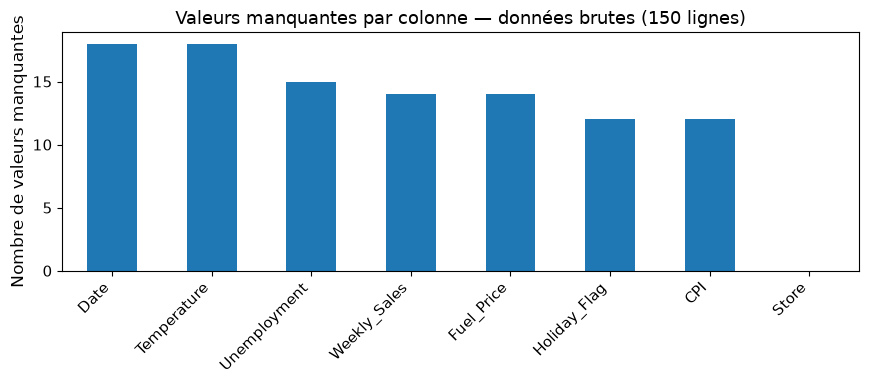

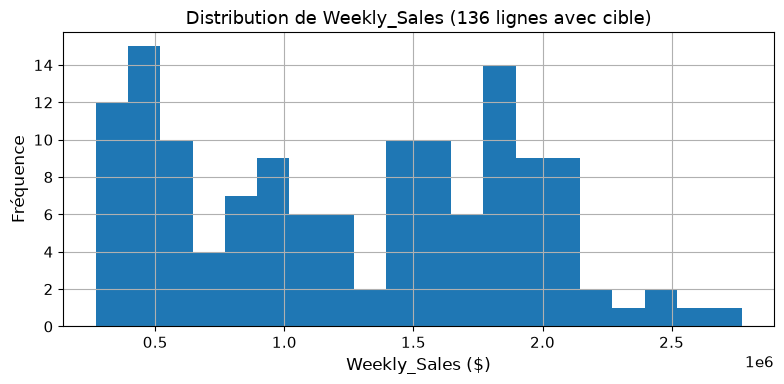

Ventes moyennes par magasin : de 302,500 $ (Store 5) à 2,173,759 $ (Store 4) ; observations par magasin : de 3 à 12.


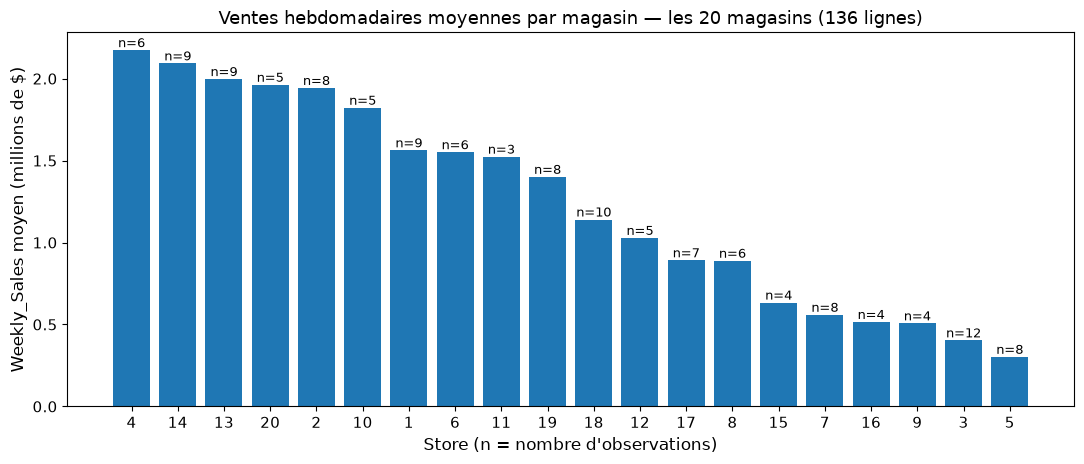

Holiday_Flag manquant (exclu de ce graphique) : 11


,moyenne,mediane,n
Holiday_Flag,,,
0.000,"1,239,575.689","1,249,738.645",116
1.000,"1,333,024.340","1,641,957.440",9


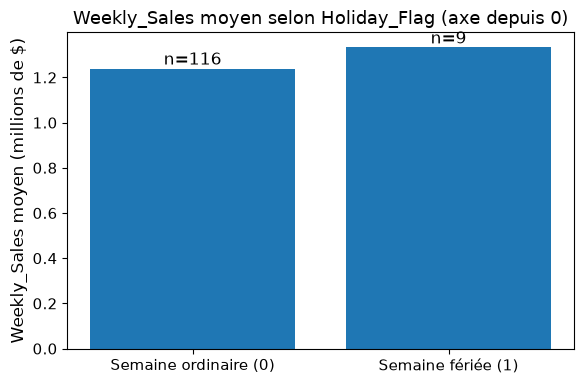

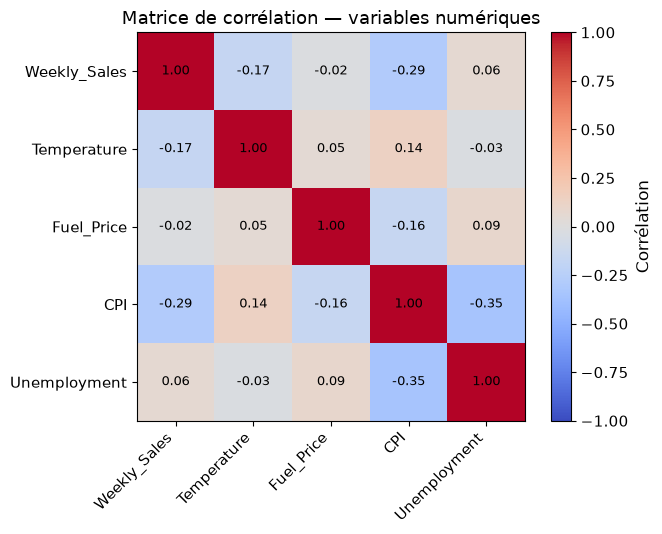

,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment
Weekly_Sales,1.000,-0.166,-0.019,-0.287,0.055
Temperature,-0.166,1.000,0.049,0.138,-0.030
Fuel_Price,-0.019,0.049,1.000,-0.160,0.086
CPI,-0.287,0.138,-0.160,1.000,-0.348
Unemployment,0.055,-0.030,0.086,-0.348,1.000


In [4]:
# =============================================================================
# 5. EDA : visualiser avant de modéliser
# =============================================================================
# Objectif : comprendre les grandes structures du jeu de données avant d'entraîner
# un modèle. Une EDA évite de traiter le ML comme une boîte noire.
#
# Base de calcul : les lignes qui ont une cible (celles qui serviront à la
# modélisation avant le filtre des outliers). Les graphiques qui portent sur les
# ventes l'indiquent dans leur titre.

# Lignes avec cible : base commune des graphiques de ventes.
ventes = df_raw.dropna(subset=["Weekly_Sales"])

# -----------------------------------------------------------------------------
# 5.1 Valeurs manquantes par colonne
# -----------------------------------------------------------------------------
# Pourquoi ? Les valeurs manquantes conditionnent les choix d'imputation.
# Alternative : supprimer toutes les lignes incomplètes. Rejetée, car le jeu est
# petit et cela ferait perdre trop d'information sur X.
plt.figure(figsize=(9, 4))
df_raw.isna().sum().sort_values(ascending=False).plot(kind="bar")
plt.title(f"Valeurs manquantes par colonne — données brutes ({len(df_raw)} lignes)")
plt.ylabel("Nombre de valeurs manquantes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

# -----------------------------------------------------------------------------
# 5.2 Distribution de la cible Weekly_Sales
# -----------------------------------------------------------------------------
# Pourquoi ? En régression, il faut connaître l'ordre de grandeur de y pour lire
# correctement MAE et RMSE. Une erreur de 180k$ n'a pas la même signification si
# les ventes valent 200k$ ou 2M$.
plt.figure(figsize=(8, 4))
ventes["Weekly_Sales"].hist(bins=20)
plt.title(f"Distribution de Weekly_Sales ({len(ventes)} lignes avec cible)")
plt.xlabel("Weekly_Sales ($)")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()
plt.close()

# -----------------------------------------------------------------------------
# 5.3 Ventes moyennes par magasin — TOUS les magasins
# -----------------------------------------------------------------------------
# Pourquoi ? Store est probablement un facteur structurel : chaque magasin a un
# bassin de clientèle, une taille et un emplacement différents.
# Le nombre d'observations (n) est écrit au-dessus de chaque barre : un magasin
# observé 2 ou 3 fois a une moyenne bien moins fiable qu'un magasin observé 10 fois.
par_magasin = (
    ventes.groupby("Store")["Weekly_Sales"]
    .agg(moyenne="mean", n="size")
    .sort_values("moyenne", ascending=False)
)
magasin_max = par_magasin["moyenne"].idxmax()
magasin_min = par_magasin["moyenne"].idxmin()
print(
    f"Ventes moyennes par magasin : de {par_magasin['moyenne'].min():,.0f} $ "
    f"(Store {int(magasin_min)}) à {par_magasin['moyenne'].max():,.0f} $ "
    f"(Store {int(magasin_max)}) ; observations par magasin : de {par_magasin['n'].min()} "
    f"à {par_magasin['n'].max()}."
)
fig, ax = plt.subplots(figsize=(11, 4.8))
barres = ax.bar([str(int(s)) for s in par_magasin.index], par_magasin["moyenne"] / 1e6)
for barre, n_obs in zip(barres, par_magasin["n"], strict=True):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height(),
        f"n={n_obs}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.set_title(
    f"Ventes hebdomadaires moyennes par magasin — les {len(par_magasin)} magasins "
    f"({len(ventes)} lignes)"
)
ax.set_xlabel("Store (n = nombre d'observations)")
ax.set_ylabel("Weekly_Sales moyen (millions de $)")
fig.tight_layout()
plt.show()
plt.close(fig)

# -----------------------------------------------------------------------------
# 5.4 Effet moyen du flag jour férié
# -----------------------------------------------------------------------------
# Pourquoi ? L'énoncé cite Holiday_Flag comme variable explicative. On vérifie si
# elle semble porter un signal moyen. Les semaines fériées sont rares : le nombre
# d'observations est affiché, et l'axe part de zéro pour ne pas exagérer l'écart.
# Les lignes dont Holiday_Flag est manquant ne peuvent pas être classées : elles
# sont exclues de ce graphique (leur nombre est affiché).
ferie = (
    ventes.dropna(subset=["Holiday_Flag"])
    .groupby("Holiday_Flag")["Weekly_Sales"]
    .agg(moyenne="mean", mediane="median", n="size")
)
print("Holiday_Flag manquant (exclu de ce graphique) :", int(ventes["Holiday_Flag"].isna().sum()))
afficher(ferie)
fig, ax = plt.subplots(figsize=(6, 4))
barres = ax.bar(["Semaine ordinaire (0)", "Semaine fériée (1)"], ferie["moyenne"] / 1e6)
for barre, n_obs in zip(barres, ferie["n"], strict=True):
    ax.text(
        barre.get_x() + barre.get_width() / 2,
        barre.get_height(),
        f"n={n_obs}",
        ha="center",
        va="bottom",
    )
ax.set_ylim(bottom=0)
ax.set_title("Weekly_Sales moyen selon Holiday_Flag (axe depuis 0)")
ax.set_ylabel("Weekly_Sales moyen (millions de $)")
fig.tight_layout()
plt.show()
plt.close(fig)

# -----------------------------------------------------------------------------
# 5.5 Corrélations numériques simples
# -----------------------------------------------------------------------------
# Pourquoi ? Les corrélations donnent une première lecture linéaire marginale.
# Limite : une corrélation faible ne prouve pas qu'une variable est inutile. Elle
# peut devenir utile une fois combinée à Store, Month ou d'autres variables.
corr_cols = ["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
corr = df_raw[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(image, ax=ax, label="Corrélation")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
# Valeur de chaque case écrite dans la case : la figure se lit sans la matrice.
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Matrice de corrélation — variables numériques")
fig.tight_layout()
plt.show()
plt.close(fig)

# Affichage numérique de la matrice pour ne pas dépendre uniquement d'un visuel.
afficher(corr)

### Lecture de l'EDA

- Le niveau de ventes varie fortement selon le magasin : `Store` est donc probablement une variable dominante. Les effectifs par magasin sont faibles (le graphique les indique) : les moyennes de magasins observés peu de fois sont fragiles.
- Les semaines fériées sont rares dans l'échantillon : la comparaison des moyennes repose sur très peu de lignes (voir les effectifs du graphique).
- Les variables macro-économiques seules ne suffisent pas à expliquer les ventes ; elles doivent être combinées avec l'identité magasin et les variables calendaires.
- Le jeu est petit et incomplet : il faut privilégier un pipeline robuste et interprétable plutôt qu'un modèle opaque sur-ajusté.

In [5]:
# =============================================================================
# 6. Prétraitement pandas imposé par l'énoncé
# =============================================================================
# On distingue volontairement deux niveaux de preprocessing.
#
# A. Préprocessing pandas métier/dataset :
#    - suppression des lignes sans cible ;
#    - extraction de variables calendaires ;
#    - suppression des outliers selon la règle imposée par l'énoncé.
#
# B. Préprocessing scikit-learn dans Pipeline :
#    - imputation des variables explicatives ;
#    - encodage des variables catégorielles ;
#    - standardisation des variables numériques.
#
# Pourquoi ne pas tout faire dans pandas ? Parce que les transformations apprises
# sur X, comme l'imputation et le scaling, doivent être ajustées sur train
# uniquement. Le Pipeline scikit-learn garantit cette discipline.


# La fonction prepare_dataframe est dans walmart_bloc3.py (testée dans tests/). Elle applique,
# dans cet ordre, les trois opérations imposées :
#
# 6.1 Suppression des lignes où la cible est manquante.
#     Pourquoi ? En supervisé, y est la vérité terrain. Imputer y fabriquerait
#     artificiellement des ventes et biaiserait l'apprentissage.
#
# 6.2 Transformation de Date en Year, Month, Day, DayOfWeek (lundi = 0, dimanche = 6).
#     Un modèle linéaire ne sait pas interpréter une chaîne comme '18-02-2011'. Une date
#     invalide devient NaT (errors='coerce') au lieu de casser le code ; les valeurs
#     calendaires manquantes seront imputées ensuite dans le Pipeline.
#
# 6.3 Filtrage des valeurs hors de [moyenne - N_SIGMA σ, moyenne + N_SIGMA σ], colonne par
#     colonne. L'énoncé impose cette règle ; on l'applique donc, même si en production on
#     apprendrait les seuils sur le train uniquement. Les NaN de X ne sont pas des valeurs
#     extrêmes : ils seront imputés dans le Pipeline. Une ligne déjà exclue par une colonne
#     n'est pas recomptée par la suivante.
#
# Les deux réglages ci-dessous sont ICI pour pouvoir être changés en direct (retirer
# "Unemployment" de OUTLIER_COLS, passer N_SIGMA à 4 ou 5), puis relancer à partir de cette
# cellule. Le journal et les seuils appliqués sont rendus en plus du jeu nettoyé.
OUTLIER_COLS = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]
N_SIGMA = 3


# Exécution du nettoyage pandas.
model_df, preprocessing_report, outlier_report = prepare_dataframe(df_raw, OUTLIER_COLS, N_SIGMA)

# Contrôles post-nettoyage : taille, journal, seuils, aperçu des lignes.
print("Shape après preprocessing pandas :", model_df.shape)
afficher(preprocessing_report)
afficher(outlier_report)
afficher(model_df.head())

# -----------------------------------------------------------------------------
# 6.4 Conséquences du prétraitement imposé (à connaître avant de modéliser)
# -----------------------------------------------------------------------------
# a) Quelles lignes la règle a-t-elle retirées, et de quels magasins ?
# consequences_pretraitement compare le brut au jeu nettoyé. Si Unemployment n'est pas dans
# OUTLIER_COLS, il n'y a pas de borne de chômage : le résultat le dit (None) au lieu de planter.
consequences = consequences_pretraitement(df_raw, model_df, outlier_report)
retirees = consequences.lignes_retirees
print(f"Lignes retirées par la règle ±{N_SIGMA:g}σ : {len(retirees)}")
afficher(retirees[["Store", "Date", "Weekly_Sales", "Unemployment"]])

print(
    f"Magasins avant la règle : {consequences.magasins_avant} ; "
    f"après : {consequences.magasins_apres}"
)
print("Magasin(s) supprimé(s) EN ENTIER :", consequences.magasins_perdus)

# Les valeurs de chômage de ces lignes, comparées à la borne haute de la règle.
if consequences.borne_haute_chomage is None:
    print("Unemployment n'est pas dans OUTLIER_COLS : aucune borne de chômage à comparer.")
else:
    avec_cible = df_raw.dropna(subset=["Weekly_Sales"])
    print(
        f"Chômage des lignes retirées : de {retirees['Unemployment'].min():.2f} à "
        f"{retirees['Unemployment'].max():.2f} (borne haute de la règle : "
        f"{consequences.borne_haute_chomage:.2f}) ; "
        f"chômage moyen de l'ensemble : {avec_cible['Unemployment'].mean():.2f}"
    )

# b) DayOfWeek : combien de valeurs différentes ?
jours = model_df["DayOfWeek"].value_counts(dropna=False)
print("\nValeurs de DayOfWeek (0 = lundi ... 4 = vendredi) :", jours.to_dict())

# c) Dates manquantes : combien de lignes, et ces lignes vendent-elles autrement ?
sans_date = model_df["Year"].isna()
print(
    f"\nLignes sans date dans le jeu de modélisation : {int(sans_date.sum())} sur {len(model_df)}"
)
comparaison_dates = model_df.groupby(sans_date)["Weekly_Sales"].agg(["count", "mean", "median"])
comparaison_dates.index = ["date connue", "date manquante"]
afficher(comparaison_dates)
print("Années présentes :", sorted(int(a) for a in model_df["Year"].dropna().unique()))
print(
    "Médianes utilisées pour l'imputation (jeu complet, à titre indicatif) :",
    model_df[["Year", "Month", "Day"]].median().to_dict(),
)

Shape après preprocessing pandas : (131, 11)


,step,rows_before,rows_after,rows_removed,reason
0,drop_missing_target_Weekly_Sales,150,136,14,La cible y ne doit jamais être imputée.
1,create_calendar_features,136,136,0,La date brute n'est pas exploitable directemen...
2,outlier_filter_Temperature,136,136,0,Règle imposée par l'énoncé : moyenne ± 3 écart...
3,outlier_filter_Fuel_Price,136,136,0,Règle imposée par l'énoncé : moyenne ± 3 écart...
4,outlier_filter_CPI,136,136,0,Règle imposée par l'énoncé : moyenne ± 3 écart...
5,outlier_filter_Unemployment,136,131,5,Règle imposée par l'énoncé : moyenne ± 3 écart...
6,after_all_outlier_filters,136,131,5,Dataset prêt pour X/y et pipeline sklearn.


,variable,mean,std,lower_bound,upper_bound,outliers_removed
0,Temperature,60.854,18.514,5.311,116.397,0
1,Fuel_Price,3.317,0.480,1.878,4.756,0
2,CPI,178.091,40.243,57.362,298.820,0
3,Unemployment,7.666,1.619,2.807,12.524,5


Lignes retirées par la règle ±3σ : 5


Magasins avant la règle : 20 ; après : 19
Magasin(s) supprimé(s) EN ENTIER : [12]
Chômage des lignes retirées : de 13.50 à 14.31 (borne haute de la règle : 12.52) ; chômage moyen de l'ensemble : 7.67

Valeurs de DayOfWeek (0 = lundi ... 4 = vendredi) : {4.0: 113, nan: 18}

Lignes sans date dans le jeu de modélisation : 18 sur 131


,count,mean,median
date connue,113,"1,267,414.774","1,420,405.410"
date manquante,18,"1,198,826.561","1,146,179.380"


Années présentes : [2010, 2011, 2012]
Médianes utilisées pour l'imputation (jeu complet, à titre indicatif) : {'Year': 2011.0, 'Month': 6.0, 'Day': 17.0}


### Résultats du prétraitement pandas

L'énoncé impose quatre opérations, appliquées dans cet ordre : suppression des lignes sans cible (150 → 136), création des variables de date, filtre `moyenne ± 3 écarts-types` sur `Temperature`, `Fuel_Price`, `CPI` et `Unemployment` (136 → 131). Le journal ci-dessus donne le détail de chaque étape.

**Conséquence à connaître : le magasin 12 disparaît.** Les cinq lignes retirées par la règle sur `Unemployment` appartiennent toutes au magasin 12 : la règle supprime ce magasin **en entier** (la cellule ci-dessus l'affiche). Il reste 19 magasins. La consigne est appliquée à la lettre, mais le modèle ne dit donc rien du magasin 12. Ses valeurs de chômage sont groupées dans une plage étroite (voir la sortie ci-dessus) : elles décrivent plutôt un magasin situé dans une zone de chômage élevé que des erreurs de saisie ; avec une règle apprise magasin par magasin, ou avec un seuil plus large, ces lignes auraient pu être conservées. C'est une limite de l'étude, pas un défaut caché.

**`DayOfWeek` est constant.** Toutes les dates connues sont des vendredis (valeur 4) : les données Walmart sont hebdomadaires, datées du même jour de la semaine. Une variable constante n'apporte aucune information : après standardisation elle vaut zéro partout, et son coefficient sera exactement nul (section 14). Elle est conservée parce que l'énoncé demande de créer cette variable, et pour que le pipeline reste valable si des données d'un autre jour de la semaine arrivaient.

**Dates manquantes.** Les lignes sans date ne peuvent pas être reconstruites (aucune autre colonne ne les donne) et les supprimer retirerait une part notable d'un jeu déjà petit. Elles sont donc gardées et leurs quatre variables calendaires sont imputées par la **médiane de l'apprentissage**, dans le pipeline (section 9). Cette imputation ne crée pas de date réelle ; elle place la ligne au milieu de la distribution des dates, ce qui évite d'inventer un effet de calendrier. Le tableau ci-dessus compare les ventes avec et sans date : l'échantillon est trop petit pour conclure à l'absence de lien. Limite : l'effet des variables calendaires est atténué pour ces lignes. Une alternative, non testée ici, serait d'ajouter un indicateur « date manquante ».

<div class="bloc3-decision">
<strong>Résultat opérationnel :</strong> après nettoyage, le jeu de modélisation contient <strong>131 lignes × 11 colonnes</strong> et 19 magasins. Les 14 lignes sans cible ont été supprimées, puis 5 lignes (toutes du magasin 12) par la règle outlier de l'énoncé.
</div>

### Remarque sur le risque de fuite de données

Le filtrage outlier est appliqué ici avant le découpage parce que l'énoncé demande explicitement de supprimer les valeurs hors intervalle `moyenne ± 3σ`. Dans un pipeline de production strict, les seuils d'outliers seraient plutôt appris sur `X_train` via un transformer personnalisé, puis appliqués de manière contrôlée. Cette nuance est importante à connaître, mais la consigne fournie est respectée.

In [6]:
# =============================================================================
# 7. Définition de X, y et des familles de variables
# =============================================================================
# Objectif : séparer clairement la cible y des variables explicatives X.
# Cette séparation est obligatoire en apprentissage supervisé.
#
# y = Weekly_Sales : valeur à prédire.
# X = informations disponibles pour produire cette prédiction.

# Nom explicite de la cible pour éviter les chaînes de caractères répétées.
target = "Weekly_Sales"

# Variables catégorielles.
# Store est un identifiant nominal : Store 20 n'est pas deux fois Store 10.
# Holiday_Flag est binaire, mais le traiter comme catégorie évite d'imposer une
# distance numérique qui ne porte pas nécessairement un sens métier linéaire.
categorical_features = ["Store", "Holiday_Flag"]

# Variables numériques conservées.
# Elles seront imputées puis standardisées dans le Pipeline scikit-learn.
numeric_features = [
    "Temperature",  # contexte météo : peut influencer la fréquentation et certains achats
    "Fuel_Price",  # contexte économique : coût du carburant et mobilité clients
    "CPI",  # indice des prix : proxy inflation/pouvoir d'achat
    "Unemployment",  # contexte socio-économique local
    "Year",  # tendance temporelle annuelle
    "Month",  # saisonnalité commerciale
    "Day",  # composante jour du mois demandée par l'énoncé
    "DayOfWeek",  # jour de semaine issu de la date (constant : voir section 6)
]

# X contient uniquement les variables autorisées pour prédire.
# On n'inclut pas Weekly_Sales dans X pour éviter une fuite directe de la cible.
X = model_df[categorical_features + numeric_features]

# y est isolée dans un objet séparé pour l'entraînement supervisé.
y = model_df[target]

# Contrôles de cohérence : ils montrent exactement combien de
# lignes et de variables entrent dans le modèle.
print("Shape X :", X.shape)
print("Shape y :", y.shape)
print("Variables catégorielles :", categorical_features)
print("Variables numériques :", numeric_features)

# Aperçu de X après feature engineering, avant preprocessing sklearn.
afficher(X.head())

Shape X : (131, 10)
Shape y : (131,)
Variables catégorielles : ['Store', 'Holiday_Flag']
Variables numériques : ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Day', 'DayOfWeek']


In [7]:
# =============================================================================
# 8. Découpage train/test
# =============================================================================
# Objectif : mesurer la capacité de généralisation sur des lignes non utilisées
# pour entraîner le modèle.
#
# Point central anti-fuite : on découpe AVANT d'ajuster l'imputation, le scaling
# et l'encodage. Ces opérations seront ensuite apprises uniquement sur X_train via
# le Pipeline.
#
# Pourquoi test_size=0.20 ?
# - C'est un compromis standard : assez de train pour apprendre, assez de test
#   pour évaluer.
# - Le dataset est petit, donc un test beaucoup plus grand affaiblirait fortement
#   l'apprentissage.
#
# Pourquoi pas stratify ?
# - stratify est naturel en classification.
# - Ici y est continue : c'est une régression.
#
# Alternative crédible : split temporel.
# - En production forecasting, il serait souvent préférable.
# - Ici, l'énoncé attend surtout une comparaison reproductible train/test sur un
#   dataset réduit et partiellement incomplet.

X_train, X_test, y_train, y_test = train_test_split(
    X,  # variables explicatives
    y,  # cible continue
    test_size=0.20,  # 20 % des lignes réservées au test
    random_state=RANDOM_STATE,  # reproductibilité exacte du découpage
)

# Contrôles de distribution : si les moyennes train/test étaient extrêmement
# différentes, l'évaluation serait plus instable.
print("Taille train :", X_train.shape[0])
print("Taille test  :", X_test.shape[0])
print("Moyenne y_train :", round(y_train.mean(), 2))
print("Moyenne y_test  :", round(y_test.mean(), 2))

Taille train : 104
Taille test  : 27
Moyenne y_train : 1279744.69
Moyenne y_test  : 1174196.28


In [8]:
# =============================================================================
# 9. Pipeline scikit-learn de prétraitement
# =============================================================================
# Objectif : construire un préprocesseur robuste qui transforme les données
# hétérogènes en matrice numérique exploitable par les modèles linéaires.
#
# Pourquoi un Pipeline / ColumnTransformer plutôt que du prétraitement manuel ?
# - Il évite la fuite de données : fit sur train, transform sur test.
# - Il rend le workflow reproductible et industrialisable.
# - Il garantit que les mêmes transformations sont appliquées à tous les modèles.
#
# Choix techniques et alternatives :
# - Numériques : médiane + StandardScaler.
#   Alternative moyenne : plus sensible aux valeurs extrêmes.
#   Alternative MinMaxScaler : plus sensible aux bornes, moins adapté ici.
#   La médiane sert aussi à imputer les dates manquantes (voir section 6).
# - Catégorielles : mode + OneHotEncoder.
#   Alternative LabelEncoder : rejetée, car elle créerait un ordre artificiel.
# - OneHotEncoder(drop='first') : évite une colinéarité parfaite entre dummies.
#   La modalité supprimée devient la RÉFÉRENCE des coefficients (section 14).
# - handle_unknown='ignore' : rend le pipeline robuste si une catégorie absente
#   du train apparaît au test (elle est alors codée comme la référence).

# Pipeline numérique :
# 1. Imputation médiane : robuste aux valeurs extrêmes et adaptée aux variables continues.
# 2. Standardisation : nécessaire pour comparer correctement les coefficients pénalisés
#    par Ridge/Lasso. Sans scaling, une variable à grande échelle serait pénalisée
#    différemment d'une variable à petite échelle.
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Pipeline catégoriel :
# 1. Imputation par la modalité la plus fréquente : choix simple et stable.
# 2. One-hot encoding : transforme les catégories en colonnes binaires exploitables.
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
        ),
    ]
)

# ColumnTransformer applique chaque pipeline au bon sous-ensemble de colonnes.
# remainder='drop' par défaut : seules les colonnes explicitement listées passent.
# C'est souhaitable ici : aucune colonne non maîtrisée ne doit entrer dans le modèle.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)


# build_pipeline(model, preprocessor) est dans walmart_bloc3.py (testée) : elle assemble le
# prétraitement et le modèle dans un Pipeline.
#
# Pourquoi clone(preprocessor) à l'intérieur ?
# Chaque modèle doit avoir son propre objet de prétraitement. Sinon, plusieurs pipelines
# pourraient partager un état interne après fit, ce qui rendrait les comparaisons moins
# propres.


# Affichage de l'objet pour vérifier visuellement la structure du pipeline.
afficher(preprocessor)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [9]:
# =============================================================================
# 10. Fonctions d'évaluation
# =============================================================================
# Objectif : centraliser le calcul des métriques pour évaluer tous les modèles
# exactement de la même manière.
#
# Métriques retenues :
# - RMSE : erreur dans l'unité métier ($), pénalise fortement les grosses erreurs.
# - MAE  : erreur moyenne absolue, plus robuste et directement lisible.
# - R²   : part de variance expliquée ; utile pour comparer à une baseline naïve.
#
# Pourquoi ne pas utiliser accuracy ? Parce que nous sommes en régression, pas en
# classification. Accuracy n'a aucun sens pour une cible continue.


# Les fonctions rmse et evaluate_model et le scorer RMSE_SCORER sont dans walmart_bloc3.py
# (testées dans tests/) :
# - rmse(y_true, y_pred) : racine de l'erreur quadratique moyenne, dans l'unité de la cible ;
# - RMSE_SCORER : scorer compatible avec GridSearchCV. scikit-learn maximise les scores, donc
#   greater_is_better=False transforme le RMSE en score négatif ; les best_score_ se lisent en
#   prenant l'opposé ;
# - evaluate_model(nom, pipeline, X_train, X_test, y_train, y_test) : évalue un pipeline déjà
#   entraîné sur l'apprentissage ET sur le test. Train : capacité à apprendre les données
#   vues ; test : généralisation ; l'écart test - train du RMSE signale un risque
#   d'overfitting.


Ridge : alpha retenu = 0.03162 (RMSE de validation croisée = 151,079 $) ; à l'intérieur de la grille : True
Lasso : alpha retenu = 316.2 (RMSE de validation croisée = 150,194 $) ; à l'intérieur de la grille : True


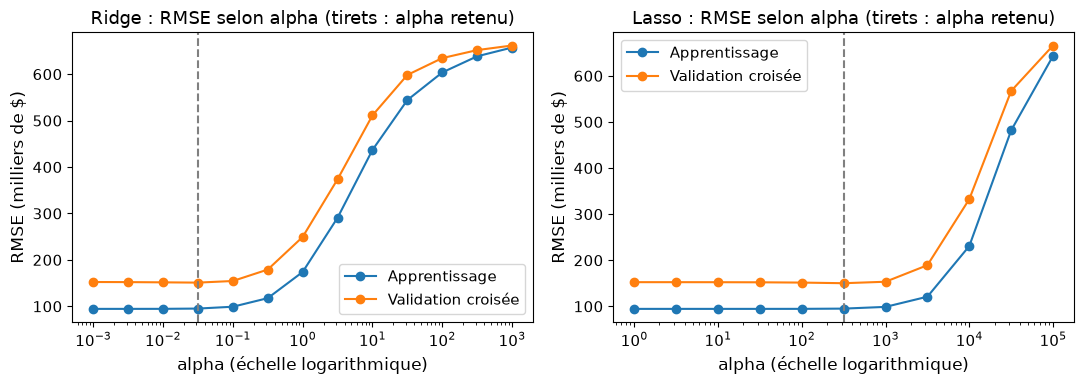

,model,cv_RMSE_mean,cv_RMSE_std
0,DummyMean,"668,514.079","51,656.940"
1,LinearRegression,"152,474.711","12,468.296"
2,"Ridge, α choisi par CV (α=0.0316)","151,079.335","13,474.674"
3,"Lasso, α choisi par CV (α=316)","150,193.891","11,905.529"


Modèle retenu (critère : RMSE de validation croisée sur l'apprentissage) : Lasso, α choisi par CV (α=316)


In [10]:
# =============================================================================
# 11. Modèles supervisés : référence, régression linéaire, Ridge, Lasso
# =============================================================================
# Objectif : entraîner les modèles demandés par l'énoncé, les comparer à une
# référence naïve, et choisir le modèle ET son hyperparamètre sans jamais regarder
# le jeu de test.
#
# Ordre de construction :
# 1. DummyRegressor : référence minimale.
# 2. LinearRegression : baseline linéaire demandée.
# 3. Ridge : régularisation L2, réduit les coefficients sans les annuler.
# 4. Lasso : régularisation L1, peut mettre certains coefficients à zéro.
#
# Choix de alpha (force de la régularisation) :
# - une GRILLE EN ÉCHELLE LOGARITHMIQUE (np.logspace) : alpha agit
#   multiplicativement, donc on le fait varier par puissances de 10 ;
# - GridSearchCV choisit alpha par validation croisée 5 plis sur le jeu
#   d'apprentissage seul. Le jeu de test n'intervient pas ;
# - le MODÈLE retenu (linéaire, Ridge ou Lasso) est aussi choisi sur le RMSE de
#   validation croisée, pas sur le RMSE de test. Choisir sur le test reviendrait à
#   utiliser les réponses du jeu de test pour fabriquer le modèle.
#
# Scoring : le RMSE négatif (scikit-learn maximise toujours un score).

# Dictionnaire qui contiendra tous les pipelines entraînés, et leur nom court
# (pour les graphiques).
models = {}
noms_courts = {}

# -----------------------------------------------------------------------------
# 11.1 DummyRegressor : référence naïve
# -----------------------------------------------------------------------------
# Il prédit la moyenne de y_train pour toutes les lignes.
# Ce modèle ne prétend pas être bon ; il sert de seuil minimal de performance.
dummy_model = build_pipeline(DummyRegressor(strategy="mean"), preprocessor)
dummy_model.fit(X_train, y_train)
models["DummyMean"] = dummy_model
noms_courts["DummyMean"] = "Référence (moyenne)"

# -----------------------------------------------------------------------------
# 11.2 LinearRegression : baseline principale demandée par l'énoncé
# -----------------------------------------------------------------------------
# Régression linéaire ordinaire : pas de régularisation.
# Avantage : interprétable.
# Limite : peut être instable avec beaucoup de variables one-hot et peu de lignes.
linear_model = build_pipeline(LinearRegression(), preprocessor)
linear_model.fit(X_train, y_train)
models["LinearRegression"] = linear_model
noms_courts["LinearRegression"] = "Régression linéaire"

# -----------------------------------------------------------------------------
# 11.3 Validation croisée
# -----------------------------------------------------------------------------
# KFold avec shuffle=True : chaque pli contient un mélange des observations.
# random_state : les plis sont reproductibles.
# n_splits=5 : compromis classique. Avec 104 lignes d'apprentissage, plus de plis
# donnerait des validations très petites et instables.
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# -----------------------------------------------------------------------------
# 11.4 Grilles d'alpha en échelle logarithmique
# -----------------------------------------------------------------------------
# Ridge : de 10^-3 à 10^3, 13 valeurs (deux par puissance de 10).
# Lasso : de 10^0 à 10^5, 11 valeurs. Les plages diffèrent car la cible est en
# dollars (de l'ordre de 10^6) : la pénalité L1 doit être grande pour agir.
# Aucune valeur n'est choisie à la main : le optimum doit être À L'INTÉRIEUR de la
# grille (vérifié plus bas), sinon on élargirait la plage.
RIDGE_ALPHAS = np.logspace(-3, 3, 13)
LASSO_ALPHAS = np.logspace(0, 5, 11)


# chercher_alpha(estimateur, alphas, decoupage, X_app, y_app, preprocessor) est dans
# walmart_bloc3.py (testée) : elle choisit alpha par validation croisée sur (X_app, y_app)
# uniquement et rend le GridSearchCV ajusté ; best_estimator_ est le pipeline complet
# (prétraitement + modèle) réajusté sur tout (X_app, y_app) avec le meilleur alpha.
ridge_grid = chercher_alpha(
    Ridge(max_iter=10_000), RIDGE_ALPHAS, cv, X_train, y_train, preprocessor
)
lasso_grid = chercher_alpha(
    Lasso(max_iter=100_000), LASSO_ALPHAS, cv, X_train, y_train, preprocessor
)

alpha_ridge = float(ridge_grid.best_params_["model__alpha"])
alpha_lasso = float(lasso_grid.best_params_["model__alpha"])
ridge_name = f"Ridge, α choisi par CV (α={alpha_ridge:.3g})"
lasso_name = f"Lasso, α choisi par CV (α={alpha_lasso:.3g})"
models[ridge_name] = ridge_grid.best_estimator_
models[lasso_name] = lasso_grid.best_estimator_
noms_courts[ridge_name] = f"Ridge (CV, α={alpha_ridge:.3g})"
noms_courts[lasso_name] = f"Lasso (CV, α={alpha_lasso:.3g})"

# Contrôle : l'alpha retenu ne doit pas être au bord de la grille.
for nom, recherche, grille in [
    ("Ridge", ridge_grid, RIDGE_ALPHAS),
    ("Lasso", lasso_grid, LASSO_ALPHAS),
]:
    position = int(np.argmin(np.abs(grille - recherche.best_params_["model__alpha"])))
    interieur = 0 < position < len(grille) - 1
    print(
        f"{nom} : alpha retenu = {recherche.best_params_['model__alpha']:.4g} "
        f"(RMSE de validation croisée = {-recherche.best_score_:,.0f} $) ; "
        f"à l'intérieur de la grille : {interieur}"
    )

# -----------------------------------------------------------------------------
# 11.5 Courbes de validation : RMSE selon alpha
# -----------------------------------------------------------------------------
# Une courbe plate autour de l'optimum montre que le choix précis d'alpha compte peu.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nom, recherche, grille in [
    (axes[0], "Ridge", ridge_grid, RIDGE_ALPHAS),
    (axes[1], "Lasso", lasso_grid, LASSO_ALPHAS),
]:
    ax.plot(
        grille,
        -recherche.cv_results_["mean_train_score"] / 1000,
        marker="o",
        label="Apprentissage",
    )
    ax.plot(
        grille,
        -recherche.cv_results_["mean_test_score"] / 1000,
        marker="o",
        label="Validation croisée",
    )
    ax.axvline(recherche.best_params_["model__alpha"], linestyle="--", color="gray")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (échelle logarithmique)")
    ax.set_ylabel("RMSE (milliers de $)")
    ax.set_title(f"{nom} : RMSE selon alpha (tirets : alpha retenu)")
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

# -----------------------------------------------------------------------------
# 11.6 Tableau de validation croisée de tous les modèles (critère de sélection)
# -----------------------------------------------------------------------------
# Pour la régression linéaire et la référence, cross_validate rejoue les mêmes 5 plis.
# Pour Ridge et Lasso, les scores du meilleur alpha viennent de la recherche.
lignes_cv = []
for nom, pipeline in [("DummyMean", dummy_model), ("LinearRegression", linear_model)]:
    scores = cross_validate(clone(pipeline), X_train, y_train, cv=cv, scoring=RMSE_SCORER)
    lignes_cv.append(
        {
            "model": nom,
            "cv_RMSE_mean": -scores["test_score"].mean(),
            "cv_RMSE_std": scores["test_score"].std(),
        }
    )
for nom, recherche in [(ridge_name, ridge_grid), (lasso_name, lasso_grid)]:
    lignes_cv.append(
        {
            "model": nom,
            "cv_RMSE_mean": -recherche.best_score_,
            "cv_RMSE_std": recherche.cv_results_["std_test_score"][recherche.best_index_],
        }
    )
cv_table = pd.DataFrame(lignes_cv)
afficher(cv_table)

# Règle de sélection : le plus petit RMSE de validation croisée parmi les trois modèles
# linéaires (la référence naïve ne concourt pas, elle sert de plancher).
candidats = cv_table[cv_table["model"] != "DummyMean"]
best_name = str(candidats.sort_values("cv_RMSE_mean").iloc[0]["model"])
best_model = models[best_name]
print("Modèle retenu (critère : RMSE de validation croisée sur l'apprentissage) :", best_name)

In [11]:
# =============================================================================
# 12. Comparaison finale sur le jeu de test
# =============================================================================
# Objectif : mesurer, UNE fois, la généralisation de chaque modèle sur des lignes
# jamais utilisées ni pour entraîner ni pour choisir.
#
# Le modèle retenu a été choisi en section 11 sur la validation croisée. Le tableau
# ci-dessous le confirme (ou non) sur le test, mais ne le décide pas.
#
# Métriques : RMSE (dollars, pénalise les grosses erreurs), MAE (erreur moyenne
# typique) et R² (part de variance expliquée).

# evaluate_model est appelé de manière identique pour chaque pipeline : on évite un
# biais d'évaluation où certains modèles seraient mesurés avec des règles différentes.
metrics = (
    pd.DataFrame(
        [
            evaluate_model(name, model, X_train, X_test, y_train, y_test)
            for name, model in models.items()
        ]
    )
    .merge(cv_table, on="model")
    .sort_values("cv_RMSE_mean")
    .reset_index(drop=True)
)
afficher(metrics)


# fr(valeur, decimales) est dans walmart_bloc3.py : nombre au format français, espace pour
# les milliers.

# Verdict calculé : aucune valeur n'est écrite à la main.
retenu = metrics.loc[metrics["model"] == best_name].iloc[0]
ecart_rmse_pct = 100 * retenu["overfit_gap_RMSE"] / retenu["train_RMSE"]
afficher_markdown(
    f"**Modèle retenu : {best_name}**, choisi sur le RMSE de validation croisée "
    f"({fr(retenu['cv_RMSE_mean'])} $ ± {fr(retenu['cv_RMSE_std'])}).  \n"
    f"Sur le jeu de test ({len(X_test)} lignes) : **RMSE {fr(retenu['test_RMSE'])} $**, "
    f"MAE {fr(retenu['test_MAE'])} $, **R² {retenu['test_R2']:.3f}**.  \n"
    f"À l'apprentissage : R² {retenu['train_R2']:.3f}, RMSE {fr(retenu['train_RMSE'])} $ ; "
    f"le RMSE de test est {ecart_rmse_pct:.0f} % plus élevé que celui de "
    "l'apprentissage (sur-apprentissage modéré, discuté en sections 13 et 16)."
)

,model,train_R2,test_R2,train_RMSE,test_RMSE,train_MAE,test_MAE,overfit_gap_RMSE,cv_RMSE_mean,cv_RMSE_std
0,"Lasso, α choisi par CV (α=316)",0.978,0.901,"100,419.332","185,827.336","76,893.829","145,106.481","85,408.003","150,193.891","11,905.529"
1,"Ridge, α choisi par CV (α=0.0316)",0.978,0.899,"100,433.482","187,089.631","77,094.060","143,948.181","86,656.149","151,079.335","13,474.674"
2,LinearRegression,0.978,0.898,"100,070.611","188,477.527","77,220.078","145,802.667","88,406.917","152,474.711","12,468.296"
3,DummyMean,0.000,-0.032,"669,559.775","598,753.455","597,484.333","531,906.220","-70,806.320","668,514.079","51,656.940"


**Modèle retenu : Lasso, α choisi par CV (α=316)**, choisi sur le RMSE de validation croisée (150 194 $ ± 11 906).  
Sur le jeu de test (27 lignes) : **RMSE 185 827 $**, MAE 145 106 $, **R² 0.901**.  
À l'apprentissage : R² 0.978, RMSE 100 419 $ ; le RMSE de test est 85 % plus élevé que celui de l'apprentissage (sur-apprentissage modéré, discuté en sections 13 et 16).

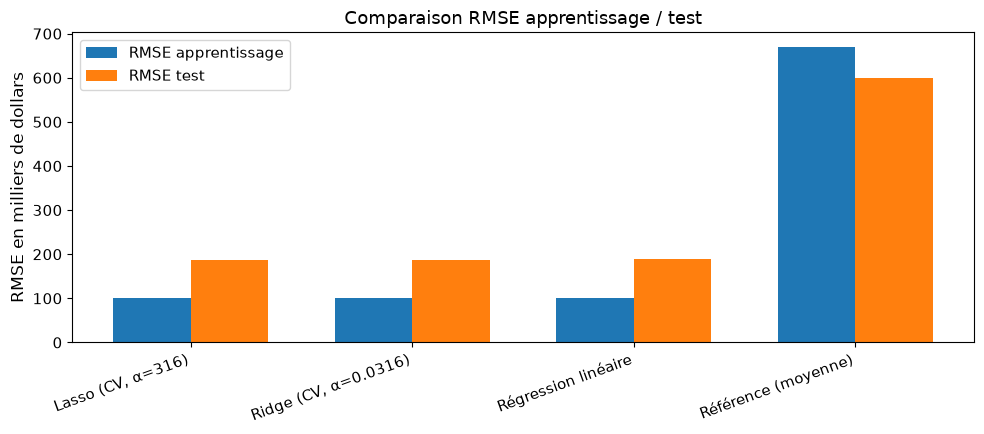

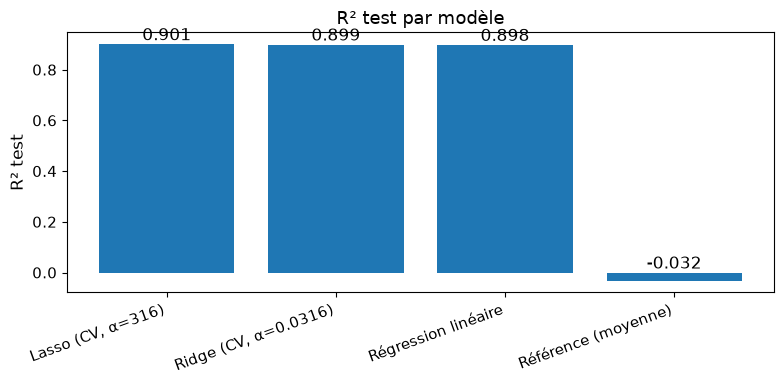

In [12]:
# =============================================================================
# 13. Visualisation des performances
# =============================================================================
# Objectif : rendre la comparaison des modèles lisible en quelques secondes.
# Les tableaux sont précis ; les graphiques permettent une lecture rapide.

# Copie de sécurité : on ne modifie pas le DataFrame metrics original.
plot_metrics = metrics.copy()

# Nom court pour éviter des labels trop longs sur l'axe x.
plot_metrics["short_model"] = plot_metrics["model"].map(noms_courts)

# -----------------------------------------------------------------------------
# 13.1 RMSE train/test
# -----------------------------------------------------------------------------
# Ce graphique permet d'identifier visuellement :
# - la performance absolue ;
# - l'écart train/test (le sur-apprentissage) ;
# - la supériorité nette des modèles linéaires face à la référence naïve.
plt.figure(figsize=(10, 4.5))
x = np.arange(len(plot_metrics))
width = 0.35
plt.bar(x - width / 2, plot_metrics["train_RMSE"] / 1000, width, label="RMSE apprentissage")
plt.bar(x + width / 2, plot_metrics["test_RMSE"] / 1000, width, label="RMSE test")
plt.title("Comparaison RMSE apprentissage / test")
plt.ylabel("RMSE en milliers de dollars")
plt.xticks(x, plot_metrics["short_model"], rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

# -----------------------------------------------------------------------------
# 13.2 R² test
# -----------------------------------------------------------------------------
# Le R² complète le RMSE : il donne une lecture relative de variance expliquée.
# Attention : le métier lit surtout des erreurs en dollars.
plt.figure(figsize=(8, 4))
barres = plt.bar(plot_metrics["short_model"], plot_metrics["test_R2"])
for barre, valeur in zip(barres, plot_metrics["test_R2"], strict=True):
    plt.text(
        barre.get_x() + barre.get_width() / 2,
        max(valeur, 0),
        f"{valeur:.3f}",
        ha="center",
        va="bottom",
    )
plt.title("R² test par modèle")
plt.ylabel("R² test")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
plt.close()

### Interprétation des performances

- Le modèle naïf est nettement moins bon : les variables explicatives apportent de l'information.
- Les trois modèles linéaires donnent des scores très proches. Le modèle retenu l'est sur la **validation croisée**, pas sur le test : l'écart avec les deux autres est faible, et la section 17 montre qu'il est plus petit que la variation due au simple choix du découpage.
- **Sur-apprentissage modéré, petit jeu de données.** Le R² est plus élevé à l'apprentissage qu'au test, et le RMSE de test dépasse nettement celui d'apprentissage (chiffres du tableau de la section 12). Les modèles linéaires régularisés ne l'annulent pas : avec 104 lignes d'apprentissage et une vingtaine de colonnes après encodage, le modèle apprend en partie des particularités de l'échantillon. L'écart est une limite à documenter, pas à cacher ; il invite à lire le score de test avec une marge, pas à rejeter le modèle.
- Le score d'un seul découpage dépend de la chance du tirage (section 17) : il ne faut jamais le présenter comme une performance certaine.

Les 12 coefficients les plus forts (en valeur absolue) :


,feature,coefficient,abs_coefficient
0,cat__Store_5.0,"-1,334,442.012","1,334,442.012"
1,cat__Store_3.0,"-1,183,306.703","1,183,306.703"
2,cat__Store_16.0,"-1,125,067.856","1,125,067.856"
3,cat__Store_9.0,"-1,113,644.276","1,113,644.276"
4,cat__Store_7.0,"-957,136.964","957,136.964"
5,cat__Store_8.0,"-773,512.419","773,512.419"
6,cat__Store_15.0,"-769,796.487","769,796.487"
7,cat__Store_17.0,"-742,927.525","742,927.525"
8,cat__Store_14.0,"604,462.759","604,462.759"
9,cat__Store_4.0,"584,200.715","584,200.715"


Variables numériques (effet d'un écart-type de la variable) :


,feature,coefficient,abs_coefficient
16,num__Month,"66,862.601","66,862.601"
17,num__Unemployment,"-62,849.689","62,849.689"
18,num__Temperature,"-60,595.053","60,595.053"
19,num__Year,"-44,317.476","44,317.476"
20,num__CPI,"43,644.934","43,644.934"
22,num__Day,"-14,811.102","14,811.102"
24,num__Fuel_Price,"-7,666.464","7,666.464"
25,num__DayOfWeek,0.000,0.000



Modalités de référence : Store 1 et Holiday_Flag = 0. Un coefficient « Store k » est l'écart de ventes hebdomadaires entre le magasin k et le magasin 1, à valeurs égales des autres variables.
Part de la variance des ventes expliquée par le seul magasin : 95.7%


,variable,part de variance entre magasins (valeurs observées),R² expliqué par les magasins (matrice prétraitée),VIF
0,Temperature,0.340,0.321,1.668
1,Fuel_Price,0.210,0.205,3.648
2,CPI,0.994,0.936,16.699
3,Unemployment,0.806,0.718,4.945
4,Year,0.201,0.183,4.274
5,Month,0.264,0.215,1.406
6,Day,0.230,0.197,1.382


Coefficients numériques ($ par écart-type) selon l'estimateur :


,Régression linéaire,"Ridge (CV, α=0.0316)","Lasso (CV, α=316)"
num__Temperature,"-60,428.222","-60,472.588","-60,595.053"
num__Fuel_Price,"-7,468.077","-6,108.076","-7,666.464"
num__CPI,"48,864.446","52,574.789","43,644.934"
num__Unemployment,"-70,249.424","-62,068.808","-62,849.689"
num__Year,"-47,742.137","-45,638.269","-44,317.476"
num__Month,"67,412.150","67,529.391","66,862.601"
num__Day,"-15,134.583","-15,454.597","-14,811.102"
num__DayOfWeek,-0.000,0.000,0.000


Intervalles à 95 % par bootstrap (300 tirages), en $ par écart-type :


,coefficient,ic95_bas,ic95_haut,signe établi
num__Temperature,"-60,595.053","-97,794.525","-14,459.380",True
num__Fuel_Price,"-7,666.464","-54,692.467","23,012.718",False
num__CPI,"43,644.934","-92,509.870","167,321.118",False
num__Unemployment,"-62,849.689","-113,616.420","-4,669.047",True
num__Year,"-44,317.476","-74,590.066","3,712.338",False
num__Month,"66,862.601","19,858.617","103,725.818",True
num__Day,"-14,811.102","-41,429.876","15,308.819",False
num__DayOfWeek,0.000,0.000,0.000,False


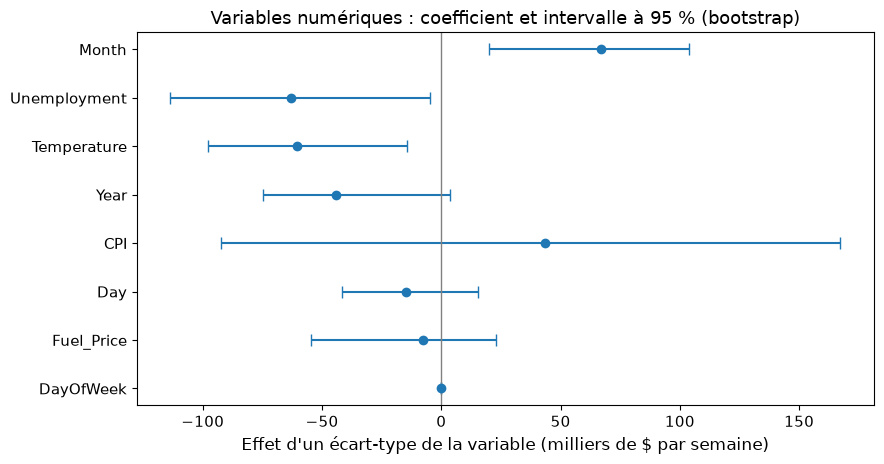

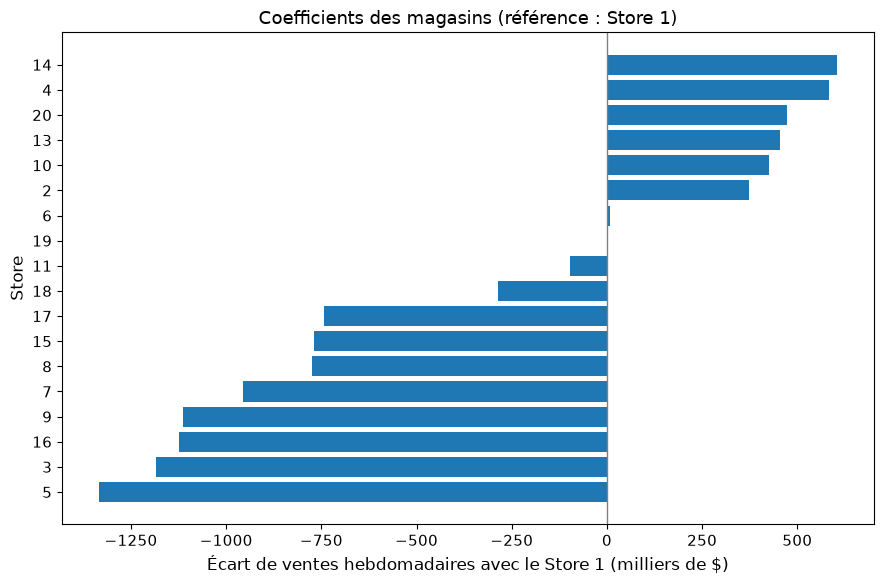

In [13]:
# =============================================================================
# 14. Coefficients du modèle retenu : lecture, limites et incertitude
# =============================================================================
# Objectif : expliquer le modèle retenu, pas seulement donner son score.
#
# Précautions d'interprétation :
# - Les variables numériques sont standardisées : un coefficient correspond à une
#   variation d'UN ÉCART-TYPE de la variable, pas d'une unité brute.
# - Les variables catégorielles sont encodées avec drop='first' : chaque
#   coefficient est un ÉCART avec une modalité de référence (identifiée ci-dessous).
# - Un coefficient fort indique une influence dans le modèle, pas une causalité.
# - Quand deux variables sont liées entre elles (colinéarité), leur coefficient
#   n'est pas fiable pris isolément : on le MESURE (VIF) et on donne un INTERVALLE
#   (bootstrap).

# -----------------------------------------------------------------------------
# 14.1 Coefficients et noms de variables
# -----------------------------------------------------------------------------
preprocess_final = best_model.named_steps["preprocess"]
feature_names = preprocess_final.get_feature_names_out()
coefs = best_model.named_steps["model"].coef_

coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coefs})
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
coef_table = coef_table.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)
colonnes_num = [c for c in feature_names if c.startswith("num__")]
colonnes_magasin = [c for c in feature_names if c.startswith("cat__Store_")]

print("Les 12 coefficients les plus forts (en valeur absolue) :")
afficher(coef_table.head(12))
print("Variables numériques (effet d'un écart-type de la variable) :")
afficher(coef_table[coef_table["feature"].isin(colonnes_num)])

# -----------------------------------------------------------------------------
# 14.2 Modalités de référence
# -----------------------------------------------------------------------------
# Avec drop='first', OneHotEncoder retire la première modalité de chaque variable :
# elle devient la référence, et ses ventes sont portées par la constante du modèle.
encodeur = preprocess_final.named_transformers_["cat"].named_steps["onehot"]
magasin_ref = int(encodeur.categories_[0][0])
ferie_ref = int(encodeur.categories_[1][0])
print(
    f"\nModalités de référence : Store {magasin_ref} et Holiday_Flag = {ferie_ref}. "
    f"Un coefficient « Store k » est l'écart de ventes hebdomadaires entre le magasin k "
    f"et le magasin {magasin_ref}, à valeurs égales des autres variables."
)

# Part de la variance de Weekly_Sales qui tient au seul magasin (jeu d'apprentissage) :
# variance entre magasins / variance totale, ce qui équivaut au R² d'une régression
# sur les seules indicatrices de magasin. C'est une grandeur comparable, contrairement
# à une somme de coefficients de natures différentes.
moyenne_magasin = y_train.groupby(X_train["Store"]).transform("mean")
part_variance_magasin = ((moyenne_magasin - y_train.mean()) ** 2).sum() / (
    (y_train - y_train.mean()) ** 2
).sum()
print(
    f"Part de la variance des ventes expliquée par le seul magasin : {part_variance_magasin:.1%}"
)

# -----------------------------------------------------------------------------
# 14.3 Colinéarité : les variables macro-économiques sont-elles distinguables du magasin ?
# -----------------------------------------------------------------------------
# Une variable économique propre à une localité varie surtout d'un magasin à l'autre.
# Quand on ajoute les indicatrices de magasin au modèle, une telle variable ne garde que
# ses variations dans le temps pour un même magasin. La part de variance située ENTRE
# magasins est mesurée pour chaque variable : elle est très inégale (voir les tableaux).
# Deux mesures sur la matrice d'apprentissage prétraitée :
# - R² de la variable expliquée par les seules indicatrices de magasin ;
# - VIF (variance inflation factor) = 1 / (1 - R²) de la variable expliquée par TOUTES
#   les autres colonnes. Règle usuelle : VIF > 10 = colinéarité forte.
Z_train = pd.DataFrame(preprocess_final.transform(X_train), columns=feature_names)
colonnes_variables = [c for c in feature_names if Z_train[c].std() > 0]  # hors constantes


# r2_regression(Z, colonne, explicatives) et part_entre_magasins(X, variable) sont dans
# walmart_bloc3.py (testées) :
# - r2_regression : R² de la régression linéaire (avec constante) de `colonne` sur
#   `explicatives`, dans la matrice prétraitée Z ;
# - part_entre_magasins : part de la variance d'une variable (valeurs OBSERVÉES, sans
#   imputation) qui tient au magasin : variance des moyennes par magasin / variance totale.
lignes_colin = []
for colonne in colonnes_num:
    if colonne not in colonnes_variables:
        continue  # DayOfWeek : constante, sans variance à expliquer
    autres = [c for c in colonnes_variables if c != colonne]
    r2_tout = r2_regression(Z_train, colonne, autres)
    nom_variable = colonne.removeprefix("num__")
    lignes_colin.append(
        {
            "variable": nom_variable,
            "part de variance entre magasins (valeurs observées)": part_entre_magasins(
                X_train, nom_variable
            ),
            "R² expliqué par les magasins (matrice prétraitée)": r2_regression(
                Z_train, colonne, colonnes_magasin
            ),
            "VIF": np.inf if r2_tout > 1 - 1e-12 else 1 / (1 - r2_tout),
        }
    )
colinearite = pd.DataFrame(lignes_colin)
afficher(colinearite)

# -----------------------------------------------------------------------------
# 14.4 Le coefficient dépend-il de la régularisation ?
# -----------------------------------------------------------------------------
# Même matrice, trois estimateurs : si un coefficient change beaucoup d'un
# estimateur à l'autre, il n'est pas déterminé par les données seules.
sensibilite = {}
for nom in ["LinearRegression", ridge_name, lasso_name]:
    pipeline = models[nom]
    noms = pipeline.named_steps["preprocess"].get_feature_names_out()
    serie = pd.Series(pipeline.named_steps["model"].coef_, index=noms)
    sensibilite[noms_courts[nom]] = serie[colonnes_num]
sensibilite = pd.DataFrame(sensibilite)
print("Coefficients numériques ($ par écart-type) selon l'estimateur :")
afficher(sensibilite)

# -----------------------------------------------------------------------------
# 14.5 Intervalles par bootstrap
# -----------------------------------------------------------------------------
# Principe : on retire 300 fois, avec remise, un échantillon de la même taille que
# l'apprentissage, on réajuste le modèle retenu (même alpha) et on garde les
# coefficients numériques. L'intervalle à 95 % est formé par les percentiles 2,5 et
# 97,5. Un intervalle qui contient 0 signifie que le signe n'est pas établi.
N_BOOTSTRAP = 300
generateur = np.random.default_rng(RANDOM_STATE)
tirages = []
for _ in range(N_BOOTSTRAP):
    indices = generateur.integers(0, len(X_train), len(X_train))
    modele_b = clone(best_model).fit(X_train.iloc[indices], y_train.iloc[indices])
    noms_b = modele_b.named_steps["preprocess"].get_feature_names_out()
    coefs_b = pd.Series(modele_b.named_steps["model"].coef_, index=noms_b)
    tirages.append(coefs_b.reindex(colonnes_num))
tirages = pd.DataFrame(tirages)
intervalles = pd.DataFrame(
    {
        "coefficient": coef_table.set_index("feature").loc[colonnes_num, "coefficient"],
        "ic95_bas": tirages.quantile(0.025),
        "ic95_haut": tirages.quantile(0.975),
    }
)
intervalles["signe établi"] = (intervalles["ic95_bas"] > 0) | (intervalles["ic95_haut"] < 0)
print(f"Intervalles à 95 % par bootstrap ({N_BOOTSTRAP} tirages), en $ par écart-type :")
afficher(intervalles)

# Les bornes sont ajoutées à la table des coefficients (vides pour les magasins).
coef_table = coef_table.join(intervalles[["ic95_bas", "ic95_haut"]], on="feature")

# -----------------------------------------------------------------------------
# 14.6 Graphiques
# -----------------------------------------------------------------------------
# a) Variables numériques avec leur intervalle : ce qui est établi, et ce qui ne l'est pas.
ordre = intervalles["coefficient"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.8))
positions = np.arange(len(ordre))
valeurs = intervalles.loc[ordre, "coefficient"] / 1000
bas = valeurs - intervalles.loc[ordre, "ic95_bas"] / 1000
haut = intervalles.loc[ordre, "ic95_haut"] / 1000 - valeurs
ax.errorbar(valeurs, positions, xerr=[bas, haut], fmt="o", capsize=4)
ax.axvline(0, color="gray", linewidth=1)
ax.set_yticks(positions, [c.removeprefix("num__") for c in ordre])
ax.set_xlabel("Effet d'un écart-type de la variable (milliers de $ par semaine)")
ax.set_title("Variables numériques : coefficient et intervalle à 95 % (bootstrap)")
fig.tight_layout()
plt.show()
plt.close(fig)

# b) Magasins : écart de ventes avec le magasin de référence.
magasins = coef_table[coef_table["feature"].isin(colonnes_magasin)].sort_values("coefficient")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    [f.removeprefix("cat__Store_").removesuffix(".0") for f in magasins["feature"]],
    magasins["coefficient"] / 1000,
)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel(f"Écart de ventes hebdomadaires avec le Store {magasin_ref} (milliers de $)")
ax.set_ylabel("Store")
ax.set_title(f"Coefficients des magasins (référence : Store {magasin_ref})")
fig.tight_layout()
plt.show()
plt.close(fig)

In [14]:
# =============================================================================
# 14.7 Lecture des coefficients (texte calculé à partir des tableaux ci-dessus)
# =============================================================================
# Les chiffres cités viennent des variables calculées en 14.2 à 14.5 : le texte ne peut
# pas contredire les sorties.
vif_par_nom = colinearite.set_index("variable")["VIF"]
entre_par_nom = colinearite.set_index("variable")[
    "part de variance entre magasins (valeurs observées)"
]


# phrase_variable(nom, intervalles, vif_par_nom, entre_par_nom) est dans walmart_bloc3.py
# (testée) : une phrase de lecture par variable, avec le lien au magasin puis l'intervalle.


afficher_markdown(
    f"""
### Lecture des coefficients

1. **Le signal dominant est l'identité du magasin.** Les coefficients « Store » sont des écarts de
   ventes par rapport au **magasin de référence (Store {magasin_ref}, la première modalité retirée
   par `drop="first"`)**, à valeurs égales des autres variables. Le magasin explique à lui seul
   {part_variance_magasin:.0%} de la variance des ventes d'apprentissage ; les variables
   calendaires et économiques pèsent bien moins.
2. **Comparer des coefficients de magasins avec ceux des variables numériques n'a pas de sens
   arithmétique** (écart à une référence d'un côté, effet d'un écart-type de l'autre) : on ne les
   additionne pas pour calculer une « part » d'influence.
3. **Les variables macro-économiques sont à lire avec prudence, pour des raisons
   différentes.** Avec les indicatrices de magasin dans le modèle, une variable ne garde que ses
   variations dans le temps pour un même magasin : cela pèse très inégalement selon la variable
   (part de variance entre magasins et VIF, section 14) :

{phrase_variable("CPI", intervalles, vif_par_nom, entre_par_nom)}
{phrase_variable("Unemployment", intervalles, vif_par_nom, entre_par_nom)}
{phrase_variable("Fuel_Price", intervalles, vif_par_nom, entre_par_nom)}
{phrase_variable("Temperature", intervalles, vif_par_nom, entre_par_nom)}

   L'intervalle est un bootstrap du modèle retenu à `alpha` fixé : il ne tient pas compte de
   l'incertitude sur le choix d'`alpha` ni sur la sélection de variables par le Lasso, et il est
   donc, si quelque chose, trop optimiste.
4. **`DayOfWeek` a un coefficient exactement nul** : toutes les dates sont des vendredis, la
   variable est constante (section 6).
5. Les coefficients décrivent le modèle, pas une causalité. Conséquence métier robuste : avant de
   planifier des campagnes nationales, il faut segmenter les magasins ; une action uniforme
   risque d'être moins efficace qu'une action différenciée par profil de magasin.
"""
)


### Lecture des coefficients

1. **Le signal dominant est l'identité du magasin.** Les coefficients « Store » sont des écarts de
   ventes par rapport au **magasin de référence (Store 1, la première modalité retirée
   par `drop="first"`)**, à valeurs égales des autres variables. Le magasin explique à lui seul
   96% de la variance des ventes d'apprentissage ; les variables
   calendaires et économiques pèsent bien moins.
2. **Comparer des coefficients de magasins avec ceux des variables numériques n'a pas de sens
   arithmétique** (écart à une référence d'un côté, effet d'un écart-type de l'autre) : on ne les
   additionne pas pour calculer une « part » d'influence.
3. **Les variables macro-économiques sont à lire avec prudence, pour des raisons
   différentes.** Avec les indicatrices de magasin dans le modèle, une variable ne garde que ses
   variations dans le temps pour un même magasin : cela pèse très inégalement selon la variable
   (part de variance entre magasins et VIF, section 14) :

- **CPI** : variable colinéaire avec les autres colonnes (VIF = 16.7, au-dessus de 10). Coefficient 43 645 $ par écart-type, intervalle à 95 % [-92 510 ; 167 321] : il contient 0 : ni le signe ni l'ordre de grandeur ne sont établis.
- **Unemployment** : variable fortement liée au magasin (81% de sa variance observée est entre magasins, VIF = 4.9, sous le seuil de 10). Coefficient -62 850 $ par écart-type, intervalle à 95 % [-113 616 ; -4 669] : il exclut 0 : le signe est établi, mais la valeur est très incertaine.
- **Fuel_Price** : variable peu liée au magasin (21% de sa variance observée est entre magasins, VIF = 3.6). Coefficient -7 666 $ par écart-type, intervalle à 95 % [-54 692 ; 23 013] : il contient 0 : ni le signe ni l'ordre de grandeur ne sont établis.
- **Temperature** : variable peu liée au magasin (34% de sa variance observée est entre magasins, VIF = 1.7). Coefficient -60 595 $ par écart-type, intervalle à 95 % [-97 795 ; -14 459] : il exclut 0 : le signe est établi, mais la valeur est très incertaine.

   L'intervalle est un bootstrap du modèle retenu à `alpha` fixé : il ne tient pas compte de
   l'incertitude sur le choix d'`alpha` ni sur la sélection de variables par le Lasso, et il est
   donc, si quelque chose, trop optimiste.
4. **`DayOfWeek` a un coefficient exactement nul** : toutes les dates sont des vendredis, la
   variable est constante (section 6).
5. Les coefficients décrivent le modèle, pas une causalité. Conséquence métier robuste : avant de
   planifier des campagnes nationales, il faut segmenter les magasins ; une action uniforme
   risque d'être moins efficace qu'une action différenciée par profil de magasin.


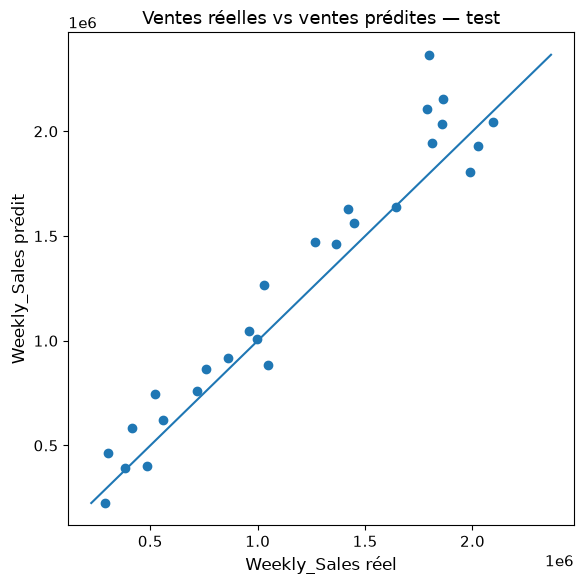

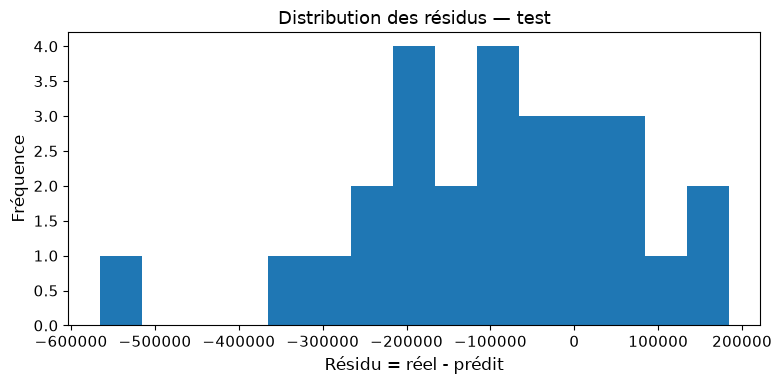

Top 10 plus grosses erreurs absolues sur le test :


Erreur absolue moyenne par magasin dans le test :


,n_test,mean_absolute_error,max_absolute_error
Store,,,
20.000,2,"442,096.417","565,813.610"
9.000,1,"223,576.719","223,576.719"
6.000,1,"206,566.800","206,566.800"
10.000,1,"184,366.129","184,366.129"
4.000,1,"175,765.041","175,765.041"
14.000,2,"170,864.413","288,242.720"
18.000,2,"162,264.987","237,976.874"
19.000,2,"148,792.504","202,949.640"
17.000,2,"136,240.661","163,629.177"


In [15]:
# =============================================================================
# 15. Diagnostic d'erreur du modèle retenu
# =============================================================================
# Objectif : dépasser la métrique moyenne.
# Une analyse sérieuse montre où le modèle se trompe, pas seulement son
# score global.
#
# Analyses produites :
# - prédictions test ;
# - résidus ;
# - erreurs absolues ;
# - top erreurs ;
# - erreur moyenne par magasin.

# Prédiction sur le jeu de test uniquement.
pred_test = best_model.predict(X_test)

# Copie de X_test pour construire une table lisible des erreurs.
prediction_diagnostic = X_test.copy()

# y_true : ventes observées ; y_pred : ventes prédites.
prediction_diagnostic["y_true"] = y_test.values
prediction_diagnostic["y_pred"] = pred_test

# Résidu signé : réel - prédit.
# Positif : le modèle sous-prédit ; négatif : le modèle sur-prédit.
prediction_diagnostic["residual"] = (
    prediction_diagnostic["y_true"] - prediction_diagnostic["y_pred"]
)

# Erreur absolue : taille de l'erreur sans tenir compte du sens.
prediction_diagnostic["absolute_error"] = prediction_diagnostic["residual"].abs()

# -----------------------------------------------------------------------------
# 15.1 Graphique réel vs prédit
# -----------------------------------------------------------------------------
# Plus les points sont proches de la diagonale, meilleur est le modèle.
plt.figure(figsize=(6, 6))
plt.scatter(prediction_diagnostic["y_true"], prediction_diagnostic["y_pred"])

# Construction dynamique des bornes pour tracer une diagonale adaptée aux données.
lims = [
    min(prediction_diagnostic["y_true"].min(), prediction_diagnostic["y_pred"].min()),
    max(prediction_diagnostic["y_true"].max(), prediction_diagnostic["y_pred"].max()),
]
plt.plot(lims, lims)
plt.title("Ventes réelles vs ventes prédites — test")
plt.xlabel("Weekly_Sales réel")
plt.ylabel("Weekly_Sales prédit")
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

# -----------------------------------------------------------------------------
# 15.2 Distribution des résidus
# -----------------------------------------------------------------------------
# Un modèle sans biais systématique devrait avoir des résidus globalement centrés
# autour de zéro. Ici, l'échantillon test est petit : on reste prudent.
plt.figure(figsize=(8, 4))
plt.hist(prediction_diagnostic["residual"], bins=15)
plt.title("Distribution des résidus — test")
plt.xlabel("Résidu = réel - prédit")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

# -----------------------------------------------------------------------------
# 15.3 Top erreurs absolues
# -----------------------------------------------------------------------------
# Pourquoi ? Les grosses erreurs sont les cas à investiguer en priorité avec les
# équipes métier : promotion manquante, événement local, rupture de stock, etc.
print("Top 10 plus grosses erreurs absolues sur le test :")
afficher(prediction_diagnostic.sort_values("absolute_error", ascending=False).head(10))

# -----------------------------------------------------------------------------
# 15.4 Erreur par magasin
# -----------------------------------------------------------------------------
# Pourquoi ? Comme Store domine les coefficients, il est cohérent de monitorer la
# qualité par magasin. Un modèle global peut être bon en moyenne et faible sur un
# segment précis.
print("Erreur absolue moyenne par magasin dans le test :")
error_by_store = (
    prediction_diagnostic.groupby("Store")
    .agg(
        n_test=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        max_absolute_error=("absolute_error", "max"),
    )
    .sort_values("mean_absolute_error", ascending=False)
)
afficher(error_by_store)

### Lecture du diagnostic d'erreur

Les plus grosses erreurs se concentrent sur quelques observations et certains magasins (voir les deux tableaux ci-dessus). Le jeu de test ne contient que 27 observations, avec un à trois points par magasin : ce diagnostic est utile pour désigner des cas à investiguer, mais il ne doit pas être surinterprété statistiquement. La diagonale réel/prédit permet de vérifier visuellement la qualité globale ; les résidus servent à détecter des erreurs systématiques.

## 16. Validation croisée K-Fold du modèle retenu

Le référentiel du bloc 3 demande explicitement « l'utilisation de la K-Fold Crossvalidation et [des] tests de vérification de sur-entrainement et sous-entrainement ». La K-Fold à 5 plis a déjà servi, en section 11, à **choisir** `alpha` (objet `cv` passé à `GridSearchCV`). Cette section la rend **visible** pour le modèle retenu : un score par pli, la moyenne, la dispersion, et l'écart entre apprentissage et validation.

**Limite à connaître :** `alpha` ayant été choisi sur ces mêmes plis, le score de validation est légèrement optimiste. La section 17 corrige ce biais en rejouant toute la procédure (choix d'`alpha` compris) sur 40 découpages différents.

In [16]:
# =============================================================================
# 16. Validation croisée K-Fold du modèle retenu, pli par pli
# =============================================================================
# cross_validate réentraîne le pipeline retenu (prétraitement + modèle) 5 fois,
# chaque fois sur 4/5 du jeu d'apprentissage, et le teste sur le 1/5 restant.
# On réutilise EXACTEMENT le même découpage `cv` que GridSearchCV (KFold à 5
# plis, mélangé, graine RANDOM_STATE) : les chiffres sont donc comparables.
# Le jeu de test (20 %) n'est jamais utilisé ici : il reste réservé à
# l'évaluation finale de la section 12.
scores_kfold = cross_validate(
    best_model,  # pipeline retenu en section 11
    X_train,
    y_train,  # apprentissage uniquement
    cv=cv,  # même KFold(5) que GridSearchCV
    scoring={"R2": "r2", "RMSE": RMSE_SCORER},
    return_train_score=True,  # pour mesurer l'écart apprentissage / validation
)

# Un tableau lisible : une ligne par pli.
# RMSE_SCORER renvoie un RMSE NÉGATIF (scikit-learn maximise toujours un
# score) : on reprend l'opposé pour lire une erreur positive, en dollars.
tableau_kfold = pd.DataFrame(
    {
        "pli": range(1, cv.get_n_splits() + 1),
        "R² apprentissage": scores_kfold["train_R2"],
        "R² validation": scores_kfold["test_R2"],
        "RMSE validation ($)": -scores_kfold["test_RMSE"],
    }
)
afficher(tableau_kfold.round(3))

moyenne_r2 = tableau_kfold["R² validation"].mean()
ecart_type_r2 = tableau_kfold["R² validation"].std()
ecart_app_val = tableau_kfold["R² apprentissage"].mean() - moyenne_r2
print(f"R² en validation croisée : {moyenne_r2:.3f} en moyenne, écart-type {ecart_type_r2:.3f}")
print(f"Écart moyen apprentissage − validation : {ecart_app_val:.3f}")

# Lecture automatique, pour que le diagnostic suive les chiffres réels.
# Seuils INDICATIFS (convention de lecture, pas une loi) :
# - SOUS-apprentissage : R² de validation faible (< 0,5) ;
# - SUR-apprentissage marqué : écart apprentissage − validation > 0,10 ;
# - SUR-apprentissage modéré : écart entre 0,02 et 0,10 ;
# - sinon : pas de sur-apprentissage visible.
# diagnostic_validation (walmart_bloc3.py, testée) applique ces seuils dans cet ordre.
diagnostic = diagnostic_validation(moyenne_r2, ecart_app_val)
print("Diagnostic en validation croisée :", diagnostic)

# Le même diagnostic sur le jeu de test (section 12) : l'écart y est plus grand.
ecart_test = retenu["train_R2"] - retenu["test_R2"]
print(
    f"Sur le jeu de test : R² {retenu['test_R2']:.3f} contre {retenu['train_R2']:.3f} à "
    f"l'apprentissage (écart {ecart_test:.3f}) ; le RMSE de test est "
    f"{ecart_rmse_pct:.0f} % plus élevé que celui d'apprentissage."
)
print(
    f"R² de validation croisée {moyenne_r2:.3f} contre R² de test {retenu['test_R2']:.3f}, "
    f"pour {len(X_train)} lignes d'apprentissage : sur un petit jeu, le score dépend du "
    "découpage (section 17)."
)

,pli,R² apprentissage,R² validation,RMSE validation ($)
0,1,0.979,0.948,"166,227.573"
1,2,0.980,0.952,"141,920.694"
2,3,0.981,0.947,"163,108.295"
3,4,0.980,0.942,"138,699.702"
4,5,0.979,0.954,"141,013.193"


R² en validation croisée : 0.949 en moyenne, écart-type 0.005
Écart moyen apprentissage − validation : 0.031
Diagnostic en validation croisée : sur-apprentissage modéré (petit jeu de données), pas de sous-apprentissage.
Sur le jeu de test : R² 0.901 contre 0.978 à l'apprentissage (écart 0.077) ; le RMSE de test est 85 % plus élevé que celui d'apprentissage.
R² de validation croisée 0.949 contre R² de test 0.901, pour 104 lignes d'apprentissage : sur un petit jeu, le score dépend du découpage (section 17).


## 17. Stabilité du résultat sur plusieurs découpages

Un seul découpage 80/20 (`random_state=42`) donne **un** score de test, sur 27 lignes. Pour savoir ce que vaut ce score, on **rejoue toute la procédure** sur 40 découpages différents : à chaque fois, découpage, choix d'`alpha` par validation croisée (Ridge et Lasso), choix du modèle sur la validation croisée, puis mesure sur le test de ce découpage.

On regarde : la moyenne et la dispersion du R² et du RMSE de test, la fréquence à laquelle chaque modèle est choisi par la validation croisée, et une comparaison **appariée** des trois modèles (mêmes découpages, donc comparables).

Un avertissement de scikit-learn peut apparaître légitimement : quand un magasin du test est absent de l'apprentissage, l'encodeur le signale (« unknown categories »). Il n'est pas masqué : il est **compté** découpage par découpage, et on regarde si le pire score s'y rattache. Tout autre avertissement serait affiché.

Autres avertissements rencontrés : aucun
Découpages où un magasin du test est absent de l'apprentissage : 18 sur 40


,R2_moyen,R2_ecart_type,R2_mediane,R2_min,R2_max,RMSE_moyen,fois_retenu_par_cv
modele,,,,,,,
Lasso,0.934,0.077,0.950,0.473,0.975,"152,007.646",28.000
LinearRegression,0.933,0.079,0.948,0.460,0.978,"153,019.898",1.000
Ridge,0.933,0.076,0.949,0.478,0.978,"152,644.158",11.000
Procédure complète (modèle choisi par CV),0.934,0.077,0.951,0.473,0.975,"152,207.948",40.000


RMSE(LinearRegression) − RMSE(Lasso) : moyenne 1,012 $ (erreur-type 1,022 $) ; Lasso meilleur dans 24 découpages sur 40
RMSE(Ridge) − RMSE(Lasso) : moyenne 637 $ (erreur-type 708 $) ; Lasso meilleur dans 22 découpages sur 40
Écart-type du RMSE de test d'un même modèle entre découpages : 55,207 $

Pire découpage : graine 30, R² de test 0.473 ; magasin du test absent de l'apprentissage : True.
Autres découpages avec un magasin inconnu : 17, R² moyen 0.945 (minimum 0.912) ; découpages sans magasin inconnu : 22, R² moyen 0.946.
Les 5 plus bas R² de test de la procédure complète :


,graine,modele,R2_test,magasin_inconnu_au_test
92,30,Lasso,0.473,True
101,33,Lasso,0.912,True
79,26,Ridge,0.914,True
41,13,Lasso,0.915,False
110,36,Lasso,0.917,False


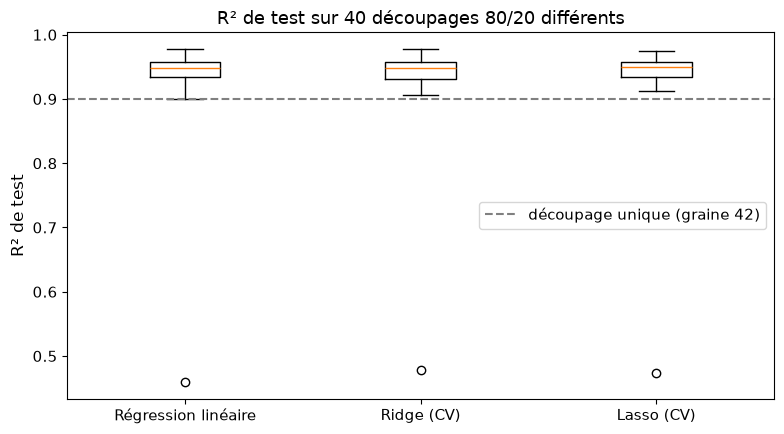

In [17]:
# =============================================================================
# 17. Stabilité sur 40 découpages train/test différents
# =============================================================================
# Pour chaque graine : découpage 80/20, choix d'alpha par validation croisée
# (Ridge et Lasso) sur l'apprentissage, régression linéaire simple, puis mesure sur
# le test de CE découpage. Le modèle « retenu par la CV » est celui dont le RMSE de
# validation croisée est le plus bas : c'est la procédure complète du notebook.
GRAINES = range(40)
MODELES_17 = {
    "LinearRegression": None,
    "Ridge": (Ridge(max_iter=10_000), RIDGE_ALPHAS),
    "Lasso": (Lasso(max_iter=100_000), LASSO_ALPHAS),
}


# evaluer_un_decoupage(graine, X, y, preprocessor, modeles) est dans walmart_bloc3.py (testée) :
# elle rejoue la procédure complète sur le découpage `graine` et rend une ligne par modèle,
# plus les avertissements autres que « unknown categories » (ceux-là sont comptés).


resultats = []
autres_avertissements = []
for graine_k in GRAINES:
    lignes_k, messages_k = evaluer_un_decoupage(graine_k, X, y, preprocessor, MODELES_17)
    resultats.extend(lignes_k)
    autres_avertissements.extend(messages_k)
decoupages = pd.DataFrame(resultats)

# Modèle retenu par la validation croisée à chaque découpage.
indice_retenu = decoupages.groupby("graine")["RMSE_CV"].idxmin()
decoupages["retenu_par_cv"] = decoupages.index.isin(indice_retenu)

print("Autres avertissements rencontrés :", autres_avertissements or "aucun")
n_inconnu = int(decoupages.groupby("graine")["magasin_inconnu_au_test"].first().sum())
print(
    "Découpages où un magasin du test est absent de l'apprentissage : "
    f"{n_inconnu} sur {len(GRAINES)}"
)

# -----------------------------------------------------------------------------
# 17.1 Résumé par modèle, et pour la procédure complète
# -----------------------------------------------------------------------------
resume = decoupages.groupby("modele").agg(
    R2_moyen=("R2_test", "mean"),
    R2_ecart_type=("R2_test", "std"),
    R2_mediane=("R2_test", "median"),
    R2_min=("R2_test", "min"),
    R2_max=("R2_test", "max"),
    RMSE_moyen=("RMSE_test", "mean"),
    fois_retenu_par_cv=("retenu_par_cv", "sum"),
)
procedure = decoupages[decoupages["retenu_par_cv"]]
resume.loc["Procédure complète (modèle choisi par CV)"] = [
    procedure["R2_test"].mean(),
    procedure["R2_test"].std(),
    procedure["R2_test"].median(),
    procedure["R2_test"].min(),
    procedure["R2_test"].max(),
    procedure["RMSE_test"].mean(),
    len(procedure),
]
afficher(resume)

# -----------------------------------------------------------------------------
# 17.2 Comparaison appariée des trois modèles (mêmes découpages)
# -----------------------------------------------------------------------------
rmse_par_modele = decoupages.pivot(index="graine", columns="modele", values="RMSE_test")
for autre in ["LinearRegression", "Ridge"]:
    difference = rmse_par_modele[autre] - rmse_par_modele["Lasso"]
    print(
        f"RMSE({autre}) − RMSE(Lasso) : moyenne {difference.mean():,.0f} $ "
        f"(erreur-type {difference.std() / np.sqrt(len(difference)):,.0f} $) ; "
        f"Lasso meilleur dans {int((difference > 0).sum())} découpages sur {len(difference)}"
    )
print(
    "Écart-type du RMSE de test d'un même modèle entre découpages : "
    f"{rmse_par_modele['Lasso'].std():,.0f} $"
)

# Le pire score s'explique-t-il par un magasin absent de l'apprentissage ? On compare le pire
# découpage, les AUTRES découpages concernés par un magasin inconnu, et les découpages sans
# magasin inconnu (procédure complète, modèle choisi par la validation croisée).
pire = procedure.loc[procedure["R2_test"].idxmin()]
inconnus = procedure[procedure["magasin_inconnu_au_test"]]
autres_inconnus = inconnus.drop(index=pire.name, errors="ignore")
connus = procedure[~procedure["magasin_inconnu_au_test"]]
print(
    f"\nPire découpage : graine {int(pire['graine'])}, R² de test {pire['R2_test']:.3f} ; "
    f"magasin du test absent de l'apprentissage : {bool(pire['magasin_inconnu_au_test'])}."
)
print(
    f"Autres découpages avec un magasin inconnu : {len(autres_inconnus)}, "
    f"R² moyen {autres_inconnus['R2_test'].mean():.3f} (minimum "
    f"{autres_inconnus['R2_test'].min():.3f}) ; découpages sans magasin inconnu : "
    f"{len(connus)}, R² moyen {connus['R2_test'].mean():.3f}."
)
print("Les 5 plus bas R² de test de la procédure complète :")
afficher(
    procedure.nsmallest(5, "R2_test")[["graine", "modele", "R2_test", "magasin_inconnu_au_test"]]
)

# -----------------------------------------------------------------------------
# 17.3 Graphique : dispersion du R² de test selon le modèle
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
modeles_ordre = ["LinearRegression", "Ridge", "Lasso"]
ax.boxplot(
    [decoupages.loc[decoupages["modele"] == m, "R2_test"] for m in modeles_ordre],
    tick_labels=["Régression linéaire", "Ridge (CV)", "Lasso (CV)"],
)
ax.axhline(retenu["test_R2"], linestyle="--", color="gray", label="découpage unique (graine 42)")
ax.set_ylabel("R² de test")
ax.set_title(f"R² de test sur {len(GRAINES)} découpages 80/20 différents")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## 18. Bonus Bloc 3 C3.3 — segmentation non supervisée des magasins

Cette section n'est pas obligatoire pour le projet Walmart Sales, mais elle couvre explicitement la compétence de segmentation non supervisée du Bloc 3.

Objectif : segmenter les magasins selon leur profil moyen : niveau de ventes, volatilité, température moyenne, carburant, CPI, chômage, part de semaines fériées. La segmentation porte sur les 19 magasins restants (le magasin 12 a disparu au prétraitement, section 6).

Pourquoi ne pas mélanger cela avec le modèle supervisé ? Parce que les objectifs sont différents :

- la régression prédit `Weekly_Sales` ;
- le clustering regroupe des magasins homogènes pour l'analyse métier.

Scores de silhouette testés :


,k,silhouette
0,2,0.213
1,3,0.235
2,4,0.248
3,5,0.204
4,6,0.226


k retenu : 4
Variance expliquée par PCA 2D : [0.35943525 0.22597315]


,cluster,n_stores,stores,sales_mean,unemployment_mean,cpi_mean,holiday_rate
0,0,3,"4, 13, 17","1,687,533.449",6.496,128.446,0.000
1,1,6,"3, 5, 6, 8, 9, 16","694,606.252",6.566,212.785,0.028
2,2,6,"1, 2, 7, 11, 14, 20","1,607,280.258",7.815,206.466,0.213
3,3,4,"10, 15, 18, 19","1,249,184.492",8.299,133.260,0.000


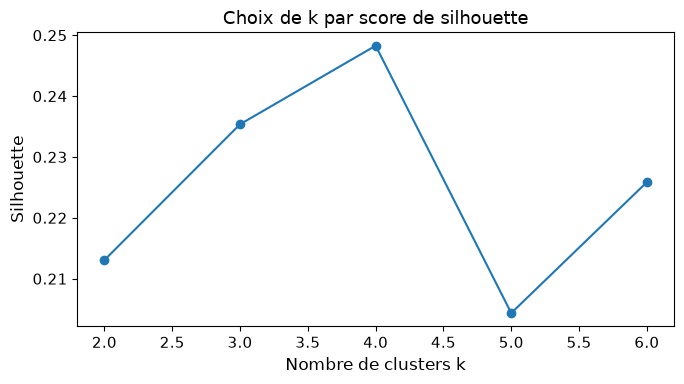

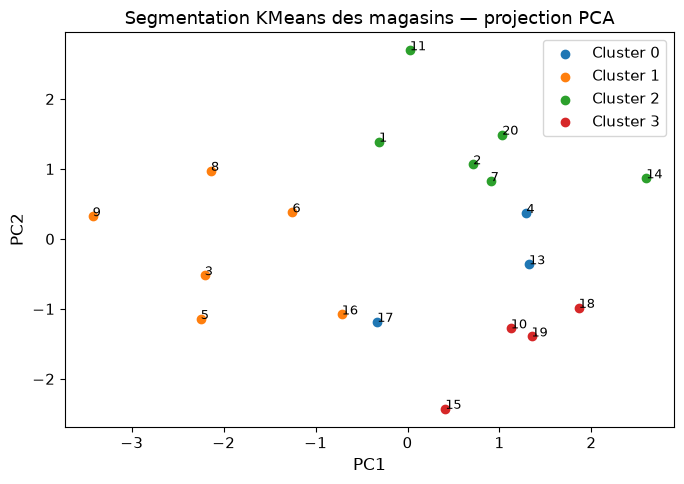

In [18]:
# =============================================================================
# 18. KMeans + PCA sur profils magasins
# =============================================================================
# Objectif : couvrir explicitement la compétence Bloc 3 liée au non-supervisé.
# Le projet Walmart est naturellement supervisé, mais on peut ajouter une analyse
# de segmentation pour comprendre les magasins de manière granulaire.
#
# Méthode :
# 1. Agréger les données au niveau Store.
# 2. Construire un profil moyen par magasin.
# 3. Imputer et standardiser ces profils.
# 4. Tester plusieurs k avec le score de silhouette.
# 5. Entraîner KMeans avec le meilleur k.
# 6. Projeter en 2D avec PCA pour visualiser.
#
# Limite assumée : peu de magasins (19), donc clustering exploratoire. On ne prétend
# pas produire une segmentation définitive de production.

# -----------------------------------------------------------------------------
# 18.1 Agrégation au niveau magasin
# -----------------------------------------------------------------------------
# On résume chaque magasin par des indicateurs moyens ou de dispersion. Cela
# transforme un dataset hebdomadaire en dataset de profils magasins.
store_profile = (
    model_df.groupby("Store")
    .agg(
        n_weeks=("Weekly_Sales", "size"),
        sales_mean=("Weekly_Sales", "mean"),
        sales_std=("Weekly_Sales", "std"),
        temp_mean=("Temperature", "mean"),
        fuel_mean=("Fuel_Price", "mean"),
        cpi_mean=("CPI", "mean"),
        unemployment_mean=("Unemployment", "mean"),
        holiday_rate=("Holiday_Flag", "mean"),
    )
    .reset_index()
)

# Si un magasin n'a qu'une observation, l'écart-type vaut NaN. On le remplace par
# 0 : avec une seule observation, aucune variabilité intra-magasin n'est observable.
store_profile["sales_std"] = store_profile["sales_std"].fillna(0)

# Variables utilisées pour segmenter les magasins.
# On n'utilise pas Store comme feature de clustering : Store est l'identifiant à
# segmenter, pas une variable explicative de similarité.
cluster_features = [
    "sales_mean",
    "sales_std",
    "temp_mean",
    "fuel_mean",
    "cpi_mean",
    "unemployment_mean",
    "holiday_rate",
]

# -----------------------------------------------------------------------------
# 18.2 Préprocessing non-supervisé
# -----------------------------------------------------------------------------
# On impute les éventuelles valeurs manquantes puis on standardise.
# StandardScaler est indispensable pour KMeans : l'algorithme repose sur des
# distances euclidiennes, donc une variable à grande échelle dominerait les autres.
unsupervised_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Z est la matrice numérique standardisée utilisée par KMeans et PCA.
Z = unsupervised_preprocessor.fit_transform(store_profile[cluster_features])

# -----------------------------------------------------------------------------
# 18.3 Recherche du nombre de clusters k
# -----------------------------------------------------------------------------
# Le score de silhouette mesure si les points sont proches de leur cluster et
# éloignés des autres clusters. Plus il est haut, mieux c'est, mais sur petit
# échantillon il doit être interprété prudemment.
silhouette_rows = []
for k in range(2, min(7, len(store_profile))):
    # n_init=30 stabilise KMeans en testant plusieurs initialisations.
    kmeans_tmp = KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE)

    # fit_predict apprend les centres et renvoie le cluster de chaque magasin.
    labels_tmp = kmeans_tmp.fit_predict(Z)

    # Stockage du score pour comparer les valeurs de k.
    silhouette_rows.append(
        {
            "k": k,
            "silhouette": silhouette_score(Z, labels_tmp),
        }
    )

# Tableau des scores de silhouette.
silhouette_table = pd.DataFrame(silhouette_rows)

# k retenu = meilleur score de silhouette.
best_k = int(silhouette_table.sort_values("silhouette", ascending=False).iloc[0]["k"])

# -----------------------------------------------------------------------------
# 18.4 Entraînement final KMeans
# -----------------------------------------------------------------------------
# KMeans final avec le k choisi précédemment.
kmeans = KMeans(n_clusters=best_k, n_init=30, random_state=RANDOM_STATE)
store_profile["cluster"] = kmeans.fit_predict(Z)

# -----------------------------------------------------------------------------
# 18.5 PCA pour visualisation
# -----------------------------------------------------------------------------
# PCA réduit les profils standardisés en 2 axes. C'est une projection de lecture,
# pas une preuve absolue de séparation des clusters.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(Z)
store_profile["PC1"] = coords[:, 0]
store_profile["PC2"] = coords[:, 1]

# Synthèse métier par cluster.
cluster_summary = (
    store_profile.groupby("cluster")
    .agg(
        n_stores=("Store", "count"),
        stores=("Store", lambda s: ", ".join(str(int(x)) for x in sorted(s))),
        sales_mean=("sales_mean", "mean"),
        unemployment_mean=("unemployment_mean", "mean"),
        cpi_mean=("cpi_mean", "mean"),
        holiday_rate=("holiday_rate", "mean"),
    )
    .reset_index()
)

# Affichages principaux.
print("Scores de silhouette testés :")
afficher(silhouette_table)
print("k retenu :", best_k)
print("Variance expliquée par PCA 2D :", pca.explained_variance_ratio_)
afficher(cluster_summary)

# -----------------------------------------------------------------------------
# 18.6 Graphique silhouette
# -----------------------------------------------------------------------------
plt.figure(figsize=(7, 4))
plt.plot(silhouette_table["k"], silhouette_table["silhouette"], marker="o")
plt.title("Choix de k par score de silhouette")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Silhouette")
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

# -----------------------------------------------------------------------------
# 18.7 Graphique PCA des clusters
# -----------------------------------------------------------------------------
plt.figure(figsize=(7, 5))
for cluster_id in sorted(store_profile["cluster"].unique()):
    subset = store_profile[store_profile["cluster"] == cluster_id]
    plt.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {cluster_id}")

    # Ajout du numéro de Store sur chaque point : indispensable pour une lecture métier.
    for _, row in subset.iterrows():
        plt.text(row["PC1"], row["PC2"], str(int(row["Store"])), fontsize=9)

plt.title("Segmentation KMeans des magasins — projection PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()
plt.close()  # évite l'accumulation de figures en exécution batch

### Lecture de la segmentation

Les scores de silhouette sont voisins pour les différentes valeurs de k testées : le choix de k=4 par le meilleur score ne repose que sur un écart faible, et la silhouette elle-même est modeste. Le clustering est donc **exploratoire** compte tenu du faible nombre de magasins ; il couvre la compétence C3.3 et propose une lecture métier (groupes de magasins aux niveaux de ventes, de chômage et de semaines fériées voisins), sans prétendre à une segmentation définitive.

## 19. Conformité RGPD

Le jeu de données Walmart ne contient **aucune donnée personnelle** : chaque ligne agrège les
ventes d'**un magasin** sur **une semaine**, accompagnées d'indicateurs économiques publics
(température, prix du carburant, indice des prix, chômage). Aucune personne physique n'est
identifiable, ni directement ni indirectement. Le RGPD, qui s'applique aux « données à caractère
personnel » (article 4.1), ne s'applique donc pas à ce traitement.

C'est une **vérification**, pas une évidence, et elle a des conséquences si le projet s'étend :

| Extension envisageable | Ce qu'elle changerait au regard du RGPD |
|---|---|
| Ajouter des données de cartes de fidélité ou de tickets de caisse | Données personnelles : base légale (art. 6), information des clients (art. 13), minimisation (art. 5.1.c), durée de conservation (art. 5.1.e) |
| Personnaliser les promotions client par client | Profilage : droit d'opposition au marketing direct (art. 21) ; analyse d'impact si le traitement est à grande échelle (art. 35) |
| Croiser avec l'adresse ou la localisation des clients | Données de localisation, identifiantes par nature : agrégation avant toute analyse |

**Ce que le projet garantit aujourd'hui** : il ne produit et n'exporte que des agrégats par
magasin et des coefficients de modèle (dossier `walmart_bloc3_exam_outputs/`).

In [19]:
# =============================================================================
# 20. Conclusion générale (texte calculé à partir des résultats ci-dessus)
# =============================================================================
# Toutes les valeurs viennent de variables calculées plus haut : la conclusion ne
# peut pas contredire les sorties.
r2_moyen_proc = procedure["R2_test"].mean()
r2_min_proc = procedure["R2_test"].min()
r2_max_proc = procedure["R2_test"].max()
ecart_rmse_lasso_lin = (rmse_par_modele["LinearRegression"] - rmse_par_modele["Lasso"]).mean()
vif_cpi = float(colinearite.set_index("variable").loc["CPI", "VIF"])
vif_chomage = float(colinearite.set_index("variable").loc["Unemployment", "VIF"])
entre_chomage = float(
    colinearite.set_index("variable").loc[
        "Unemployment", "part de variance entre magasins (valeurs observées)"
    ]
)
cpi = intervalles.loc["num__CPI"]
chomage = intervalles.loc["num__Unemployment"]
phrase_cpi = (
    "le signe du coefficient du CPI est établi"
    if cpi["signe établi"]
    else "le coefficient du CPI n'est pas établi"
)
phrase_chomage = (
    "celui du chômage a un signe stable mais une valeur très incertaine"
    if chomage["signe établi"]
    else "celui du chômage n'est pas établi non plus"
)

n = len(model_df)  # nombre de lignes du jeu de modélisation

# Magasins que la règle de la cellule 9 a fait disparaître EN ENTIER (liste vide si aucun).
perdus = consequences.magasins_perdus
if not perdus:
    phrase_perdus = f"Aucun magasin ne disparaît par la règle ±{N_SIGMA:g}σ de l'énoncé"
elif len(perdus) == 1:
    phrase_perdus = (
        f"Le magasin {perdus[0]} disparaît entièrement par la règle ±{N_SIGMA:g}σ de l'énoncé"
    )
else:
    liste_perdus = ", ".join(str(magasin) for magasin in perdus)
    phrase_perdus = (
        f"Les magasins {liste_perdus} disparaissent entièrement par la règle "
        f"±{N_SIGMA:g}σ de l'énoncé"
    )

afficher_markdown(
    f"""
### Résultat

Le pipeline complet respecte les consignes : nettoyage imposé, variables de date, découpage
train/test, prétraitement scikit-learn sans fuite, régression linéaire de référence,
régularisation Ridge/Lasso, choix de `alpha` par `GridSearchCV` sur une grille logarithmique,
métriques de régression et interprétation des coefficients.

### Décision modèle

Le modèle retenu est **{best_name}**, choisi sur le RMSE de validation croisée de l'apprentissage
({fr(retenu["cv_RMSE_mean"])} $). Sur le jeu de test : RMSE {fr(retenu["test_RMSE"])} $,
MAE {fr(retenu["test_MAE"])} $, R² {retenu["test_R2"]:.3f}.

Ce score est celui d'**un** découpage de 27 lignes. Sur {len(GRAINES)} découpages différents,
la procédure complète obtient un R² de test moyen de {r2_moyen_proc:.3f}, compris entre
{r2_min_proc:.3f} et {r2_max_proc:.3f}. L'avantage moyen du Lasso sur la régression linéaire simple
est de {fr(ecart_rmse_lasso_lin)} $ de RMSE : il est plus petit que la variation due au découpage.
Le gain du Lasso doit donc être présenté comme une amélioration marginale, pas comme une rupture.

### Message métier

Le facteur dominant est l'identité du magasin (à elle seule, {part_variance_magasin:.0%} de la
variance des ventes d'apprentissage). Les décisions marketing doivent être différenciées par
magasin ou par segment de magasins plutôt que pilotées par des variables macro-économiques
globales : {phrase_cpi} (intervalle à 95 % de {fr(cpi["ic95_bas"])} à
{fr(cpi["ic95_haut"])} $ par écart-type) et {phrase_chomage} (de {fr(chomage["ic95_bas"])} à
{fr(chomage["ic95_haut"])} $).

### Limites

1. Jeu très petit après nettoyage ({n} lignes) : les métriques dépendent du découpage (section 17).
2. Sur-apprentissage modéré : R² {retenu["train_R2"]:.3f} à l'apprentissage contre
   {retenu["test_R2"]:.3f} au test.
3. {phrase_perdus} (section 6).
4. Le filtre des outliers respecte l'énoncé, mais un pipeline de production apprendrait les
   seuils sur l'apprentissage seul.
5. La validation temporelle serait préférable avec davantage d'observations horodatées fiables.
6. Le modèle linéaire est interprétable mais ne capte pas les non-linéarités.
7. Il manque des variables métier fortes : taille du magasin, promotions, région,
   concurrence, stock.
8. Les coefficients expliquent le modèle, pas une causalité ; le CPI est colinéaire
   (VIF {vif_cpi:.1f}) et le chômage fortement lié au magasin ({entre_chomage:.0%} de sa
   variance entre magasins, VIF {vif_chomage:.1f}).
9. Le clustering KMeans est exploratoire, car le nombre de magasins est faible.

### Verdict actionnable

Utiliser le modèle **Lasso + pipeline scikit-learn** comme prototype interprétable pour prioriser
l'analyse marketing par magasin. Avant industrialisation : enrichir les données (promotions,
surface, région, concurrence, historique plus long), tester une validation temporelle et
comparer des modèles non linéaires dans un benchmark contrôlé.
"""
)


### Résultat

Le pipeline complet respecte les consignes : nettoyage imposé, variables de date, découpage
train/test, prétraitement scikit-learn sans fuite, régression linéaire de référence,
régularisation Ridge/Lasso, choix de `alpha` par `GridSearchCV` sur une grille logarithmique,
métriques de régression et interprétation des coefficients.

### Décision modèle

Le modèle retenu est **Lasso, α choisi par CV (α=316)**, choisi sur le RMSE de validation croisée de l'apprentissage
(150 194 $). Sur le jeu de test : RMSE 185 827 $,
MAE 145 106 $, R² 0.901.

Ce score est celui d'**un** découpage de 27 lignes. Sur 40 découpages différents,
la procédure complète obtient un R² de test moyen de 0.934, compris entre
0.473 et 0.975. L'avantage moyen du Lasso sur la régression linéaire simple
est de 1 012 $ de RMSE : il est plus petit que la variation due au découpage.
Le gain du Lasso doit donc être présenté comme une amélioration marginale, pas comme une rupture.

### Message métier

Le facteur dominant est l'identité du magasin (à elle seule, 96% de la
variance des ventes d'apprentissage). Les décisions marketing doivent être différenciées par
magasin ou par segment de magasins plutôt que pilotées par des variables macro-économiques
globales : le coefficient du CPI n'est pas établi (intervalle à 95 % de -92 510 à
167 321 $ par écart-type) et celui du chômage a un signe stable mais une valeur très incertaine (de -113 616 à
-4 669 $).

### Limites

1. Jeu très petit après nettoyage (131 lignes) : les métriques dépendent du découpage (section 17).
2. Sur-apprentissage modéré : R² 0.978 à l'apprentissage contre
   0.901 au test.
3. Le magasin 12 disparaît entièrement par la règle ±3σ de l'énoncé (section 6).
4. Le filtre des outliers respecte l'énoncé, mais un pipeline de production apprendrait les
   seuils sur l'apprentissage seul.
5. La validation temporelle serait préférable avec davantage d'observations horodatées fiables.
6. Le modèle linéaire est interprétable mais ne capte pas les non-linéarités.
7. Il manque des variables métier fortes : taille du magasin, promotions, région,
   concurrence, stock.
8. Les coefficients expliquent le modèle, pas une causalité ; le CPI est colinéaire
   (VIF 16.7) et le chômage fortement lié au magasin (81% de sa
   variance entre magasins, VIF 4.9).
9. Le clustering KMeans est exploratoire, car le nombre de magasins est faible.

### Verdict actionnable

Utiliser le modèle **Lasso + pipeline scikit-learn** comme prototype interprétable pour prioriser
l'analyse marketing par magasin. Avant industrialisation : enrichir les données (promotions,
surface, région, concurrence, historique plus long), tester une validation temporelle et
comparer des modèles non linéaires dans un benchmark contrôlé.


## 21. Recommandations sur les prédictions

Le livrable du bloc 3 comprend, selon le référentiel, « des recommandations sur les prédictions obtenues ». La cellule suivante les **calcule** à partir des résultats du modèle retenu, pour que chaque recommandation repose sur un chiffre affiché, et non sur une intuition. Les effets des variables économiques sont donnés **avec leur intervalle** (section 14) : une recommandation n'est formulée que si le signe est établi.

In [20]:
# =============================================================================
# 21. Recommandations calculées à partir du modèle retenu
# =============================================================================
# 1) Effet des variables économiques, exprimé dans leur UNITÉ D'ORIGINE.
#    Le modèle a appris sur des variables STANDARDISÉES (StandardScaler) : un
#    coefficient y vaut l'effet d'une hausse d'UN ÉCART-TYPE de la variable.
#    En divisant par cet écart-type (calculé sur l'apprentissage, avec ddof=0,
#    comme le fait StandardScaler), on obtient l'effet d'une hausse d'UNE unité :
#    1 °F, 1 $ de carburant, 1 point d'indice, 1 point de chômage.
#    Approximation assumée : l'imputation médiane, appliquée avant la
#    standardisation, ne touche que de rares valeurs manquantes.
#    Les bornes viennent du bootstrap de la section 14 ; le VIF mesure la colinéarité.
coefficients = coef_table.set_index("feature")["coefficient"]
vif_par_variable = colinearite.set_index("variable")["VIF"]
lignes_effets = []
for variable, unite in [
    ("Temperature", "°F"),
    ("Fuel_Price", "$ / gallon"),
    ("CPI", "point d'indice"),
    ("Unemployment", "point de %"),
]:
    cle = f"num__{variable}"
    ecart_type = X_train[variable].std(ddof=0)
    lignes_effets.append(
        {
            "variable": variable,
            "unité": unite,
            "effet d'une unité ($ / semaine)": coefficients[cle] / ecart_type,
            "IC 95 % bas": intervalles.loc[cle, "ic95_bas"] / ecart_type,
            "IC 95 % haut": intervalles.loc[cle, "ic95_haut"] / ecart_type,
            "VIF": vif_par_variable[variable],
            "signe établi": bool(intervalles.loc[cle, "signe établi"]),
        }
    )
effets = pd.DataFrame(lignes_effets)
afficher(effets.round(2))

# 2) Poids des magasins : les coefficients « cat__Store_x » mesurent l'écart de
#    ventes de chaque magasin par rapport au magasin de référence.
magasins_coefs = coefficients[coefficients.index.isin(colonnes_magasin)].sort_values()

# 3) Précision utilisable pour planifier : l'erreur absolue moyenne du modèle
#    retenu sur le jeu de test, rapportée aux ventes moyennes du test.
mae_test = retenu["test_MAE"]
erreur_relative = mae_test / y_test.mean()

print("RECOMMANDATIONS")
print(
    f"1. Piloter par magasin : l'identité du magasin explique à elle seule "
    f"{part_variance_magasin:.0%} de la variance des ventes d'apprentissage. Les écarts "
    f"de ventes vont de {fr(magasins_coefs.iloc[0])} $ à {fr(magasins_coefs.iloc[-1])} $ par "
    f"semaine par rapport au Store {magasin_ref}. Les campagnes doivent être différenciées "
    "par magasin, ou par segment de magasins (section 18)."
)
for _, e in effets.iterrows():
    effet_unitaire = e["effet d'une unité ($ / semaine)"]
    sens = "hausse" if effet_unitaire > 0 else "baisse"
    intervalle = f"IC 95 % [{fr(e['IC 95 % bas'])} ; {fr(e['IC 95 % haut'])}]"
    if e["signe établi"]:
        print(
            f"2. {e['variable']} : +1 {e['unité']} est associé à une {sens} de "
            f"{fr(abs(effet_unitaire))} $ de ventes hebdomadaires, {intervalle} "
            "(association, pas causalité)."
        )
    else:
        print(
            f"2. {e['variable']} : signe NON établi ({intervalle} contient 0) ; "
            f"aucune recommandation chiffrée n'en est tirée (VIF = {e['VIF']:.1f})."
        )
print(
    f"3. Planifier avec une marge : l'erreur absolue moyenne sur le test est de "
    f"{fr(mae_test)} $ par semaine, soit {erreur_relative:.1%} des ventes moyennes du test. "
    "Un budget ou un stock calé sur la prévision doit intégrer cette marge, et la "
    "section 17 montre qu'elle varie d'un découpage à l'autre."
)
print(
    "4. Avant tout usage en production : réentraîner chaque trimestre, suivre "
    "l'erreur réelle magasin par magasin, et ajouter les variables métier "
    "absentes (surface, promotions, concurrence locale)."
)

,variable,unité,effet d'une unité ($ / semaine),IC 95 % bas,IC 95 % haut,VIF,signe établi
0,Temperature,°F,"-3,402.560","-5,491.400",-811.930,1.670,True
1,Fuel_Price,$ / gallon,"-16,661.060","-118,859.790","50,012.130",3.650,False
2,CPI,point d'indice,"1,088.160","-2,306.470","4,171.680",16.700,False
3,Unemployment,point de %,"-63,475.020","-114,746.870","-4,715.500",4.940,True


RECOMMANDATIONS
1. Piloter par magasin : l'identité du magasin explique à elle seule 96% de la variance des ventes d'apprentissage. Les écarts de ventes vont de -1 334 442 $ à 604 463 $ par semaine par rapport au Store 1. Les campagnes doivent être différenciées par magasin, ou par segment de magasins (section 18).
2. Temperature : +1 °F est associé à une baisse de 3 403 $ de ventes hebdomadaires, IC 95 % [-5 491 ; -812] (association, pas causalité).
2. Fuel_Price : signe NON établi (IC 95 % [-118 860 ; 50 012] contient 0) ; aucune recommandation chiffrée n'en est tirée (VIF = 3.6).
2. CPI : signe NON établi (IC 95 % [-2 306 ; 4 172] contient 0) ; aucune recommandation chiffrée n'en est tirée (VIF = 16.7).
2. Unemployment : +1 point de % est associé à une baisse de 63 475 $ de ventes hebdomadaires, IC 95 % [-114 747 ; -4 716] (association, pas causalité).
3. Planifier avec une marge : l'erreur absolue moyenne sur le test est de 145 106 $ par semaine, soit 12.4% des ventes moyennes du t

## 22. Questions méthodologiques fréquentes

Cette section répond aux questions méthodologiques que ce travail soulève naturellement : chaque choix y est justifié.

| Question probable | Réponse courte à donner |
|---|---|
| Pourquoi ne pas imputer `Weekly_Sales` ? | Parce que `Weekly_Sales` est la vérité terrain. L'imputer créerait une cible artificielle et biaiserait le modèle. |
| Pourquoi imputer les variables explicatives dans un pipeline ? | Pour apprendre les valeurs d'imputation sur `X_train` uniquement et éviter que le test influence l'entraînement. |
| Pourquoi `Store` est catégoriel alors qu'il est numérique ? | Un identifiant de magasin n'a pas de distance numérique. Store 20 n'est pas deux fois Store 10. |
| Pourquoi `OneHotEncoder` plutôt que `LabelEncoder` ? | `LabelEncoder` imposerait un ordre artificiel aux magasins. `OneHotEncoder` respecte le caractère nominal. |
| Pourquoi `drop='first'` dans `OneHotEncoder` ? | Pour éviter la colinéarité parfaite entre toutes les modalités encodées et la constante du modèle linéaire. La modalité retirée (le magasin de plus petit numéro) devient la **référence** des coefficients : ils se lisent comme des écarts avec elle. |
| Pourquoi `StandardScaler` ? | Ridge et Lasso pénalisent les coefficients ; les variables doivent donc être sur des échelles comparables. |
| Pourquoi la médiane pour les numériques ? | Elle est plus robuste que la moyenne face aux valeurs extrêmes. Elle sert aussi à imputer les dates manquantes (section 6). |
| Pourquoi le mode pour les catégorielles ? | C'est une stratégie simple, stable et interprétable pour remplacer une catégorie manquante. |
| Pourquoi `train_test_split` avant le prétraitement sklearn ? | Pour éviter la fuite de données : le test ne doit pas influencer les statistiques d'imputation/scaling/encodage. |
| Pourquoi un découpage aléatoire plutôt que temporel ? | Le découpage temporel serait préférable en prévision réelle, mais l'exercice demande un pipeline de régression reproductible sur un petit jeu. La limite est explicitement annoncée. |
| Pourquoi RMSE comme critère principal ? | Il est en dollars et pénalise les grosses erreurs, ce qui est pertinent pour des prévisions de ventes. Il sert de critère de sélection **via la validation croisée sur l'apprentissage**, jamais sur le test. |
| Pourquoi conserver MAE et R² ? | MAE donne une erreur moyenne typique ; R² donne une lecture relative de variance expliquée. |
| Pourquoi ajouter `DummyRegressor` ? | Pour prouver que les modèles linéaires battent une règle naïve de prédiction moyenne. |
| Pourquoi Ridge et Lasso ? | Ils réduisent le sur-apprentissage via régularisation. Ridge réduit les coefficients ; Lasso peut aussi en annuler. |
| Pourquoi `GridSearchCV`, et pourquoi cette grille ? | Pour choisir `alpha` par validation croisée sur l'apprentissage, au lieu d'un choix arbitraire. La grille est logarithmique et `alpha` doit tomber à l'intérieur : aucune valeur n'est choisie à la main, et le test n'intervient pas. |
| Pourquoi retenir Lasso ? | Il a le plus bas RMSE de validation croisée. Son avance sur les deux autres est plus petite que la variation due au découpage (section 17) : le gain est présenté comme marginal, pas comme une rupture. |
| Le score de test est-il fiable ? | Pas à lui seul : il porte sur 27 lignes. La section 17 rejoue toute la procédure sur 40 découpages et donne la moyenne et l'étendue du R². |
| Pourquoi le magasin 12 n'apparaît-il pas ? | La règle ±3σ de l'énoncé, appliquée à `Unemployment`, retire ses cinq lignes : le magasin disparaît entièrement (section 6). C'est une conséquence de la consigne, dite et assumée. |
| Pourquoi le coefficient de `DayOfWeek` est-il nul ? | Toutes les dates sont des vendredis : la variable est constante, donc sans information (section 6). |
| Que faire des dates manquantes ? | Elles ne peuvent pas être reconstruites. Elles sont imputées par la médiane de l'apprentissage dans le pipeline ; limite : l'effet du calendrier est atténué pour ces lignes. |
| Les coefficients prouvent-ils la causalité ? | Non. Ils expliquent le comportement du modèle linéaire, toutes choses égales par ailleurs. De plus, le CPI est colinéaire (VIF supérieur à 10) et le chômage fortement lié au magasin (VIF inférieur à 10) : leurs intervalles sont larges (section 14). |
| Pourquoi un bonus KMeans ? | Pour couvrir explicitement la compétence non supervisée du Bloc 3 sans détourner le problème principal de régression. |
| Pourquoi PCA après KMeans ? | Pour visualiser les clusters en 2D. PCA n'est pas utilisé pour prédire les ventes. |
| Que manque-t-il pour une version production ? | Plus d'historique, promotions, surface magasin, localisation, concurrence, stock, événements locaux, suivi après déploiement. |

### Alternatives crédibles présentées puis rejetées

| Alternative | Pourquoi elle est crédible | Pourquoi elle n'est pas retenue ici |
|---|---|---|
| Supprimer toutes les lignes avec NaN | Simple à expliquer | Trop destructeur sur un petit jeu ; on perdrait des informations utiles sur X. |
| Imputer la cible | Permettrait de garder plus de lignes | Méthodologiquement incorrect : cela fabrique des labels. |
| Traiter `Store` comme numérique | Le CSV le stocke comme nombre | Faux sens métier : un identifiant n'est pas une grandeur continue. |
| Choisir `alpha` et le modèle sur le RMSE de test | Rapide, et donne un meilleur score apparent | Le test sert alors à fabriquer le modèle : la mesure finale devient optimiste. |
| Utiliser Random Forest / Gradient Boosting | Peut capturer des non-linéarités | Hors exigence principale ; moins interprétable sur un petit jeu ; à garder comme benchmark futur. |
| Découpage temporel strict | Plus réaliste en prévision | Le jeu est réduit et l'exercice impose surtout un pipeline de régression comparable ; la limite est documentée. |
| Supprimer le bonus KMeans | Le projet Walmart est supervisé | Le Bloc 3 exige aussi une compétence non supervisée ; le bonus la couvre proprement. |

In [21]:
# =============================================================================
# 23. Exports finaux de contrôle
# =============================================================================
# Objectif : rendre le travail auditable hors notebook.
# Ces fichiers CSV ne sont pas indispensables à la lecture du notebook, mais ils
# démontrent une démarche professionnelle : chaque résultat important peut être
# contrôlé, réutilisé ou transmis. Chaque fichier n'est écrit qu'ICI, une seule fois.
# lineterminator="\n" : fins de ligne LF sur tous les systèmes.
SORTIES = {
    # Jeu nettoyé après prétraitement pandas.
    "clean_modeling_dataset.csv": (model_df, False),
    # Comparaison des modèles supervisés (train, test, validation croisée).
    "model_metrics.csv": (metrics, False),
    # Coefficients du modèle retenu, avec intervalles par bootstrap (variables numériques).
    "best_model_coefficients.csv": (coef_table, False),
    # Colinéarité des variables numériques (R² expliqué par les magasins, VIF).
    "collinearity_vif.csv": (colinearite, False),
    # Résultat de chaque découpage de la section 17.
    "repeated_splits_results.csv": (decoupages, False),
    # Prédictions et résidus sur le test pour diagnostic ligne par ligne.
    "test_predictions_best_model.csv": (prediction_diagnostic, True),
    # Résultats du bonus non supervisé.
    "store_cluster_profile.csv": (store_profile, False),
    "silhouette_scores.csv": (silhouette_table, False),
    "cluster_summary.csv": (cluster_summary, False),
}
for nom_fichier, (table, avec_index) in SORTIES.items():
    table.to_csv(OUTPUT_DIR / nom_fichier, index=avec_index, lineterminator="\n")

# Message final explicite : si cette cellule s'exécute, le pipeline complet a tourné.
print("Exports écrits dans :", OUTPUT_DIR.name)
for nom_fichier in SORTIES:
    print(" -", nom_fichier)
print("Notebook terminé sans erreur.")

Exports écrits dans : walmart_bloc3_exam_outputs
 - clean_modeling_dataset.csv
 - model_metrics.csv
 - best_model_coefficients.csv
 - collinearity_vif.csv
 - repeated_splits_results.csv
 - test_predictions_best_model.csv
 - store_cluster_profile.csv
 - silhouette_scores.csv
 - cluster_summary.csv
Notebook terminé sans erreur.


## 24. Références utilisées

Sources à fiabilité élevée, utilisées pour cadrer le projet et les choix techniques :

- France Compétences — RNCP35288, Bloc 3 : *Analyse prédictive de données structurées par l'intelligence artificielle*. Consulté le 2026-06-05.  
  https://www.francecompetences.fr/recherche/rncp/35288/
- scikit-learn — `Pipeline` et estimateurs composites. Consulté le 2026-06-05.  
  https://scikit-learn.org/stable/modules/compose.html
- scikit-learn — `ColumnTransformer` pour données hétérogènes. Consulté le 2026-06-05.  
  https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html
- scikit-learn — `train_test_split`. Consulté le 2026-06-05.  
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- scikit-learn — métriques de régression : MAE, MSE/RMSE, R². Consulté le 2026-06-05.  
  https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
- scikit-learn — `LinearRegression`, `Ridge`, `Lasso`, `GridSearchCV`, `KMeans`, `PCA`. Consulté le 2026-06-05.  
  https://scikit-learn.org/stable/modules/linear_model.html  
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html  
  https://scikit-learn.org/stable/modules/clustering.html#k-means  
  https://scikit-learn.org/stable/modules/decomposition.html#pca